# Focused program annotation: D2 P17 and D3 P27 — version 3

## Correction to version 2
The previous notebook tried to infer P27's display cutoff from an annotated motif-name list. Your run has no parsed P27 motif list, so that branch fails. This notebook removes that dependency: the annotation workbook supplies program labels and marker genes, **not the stopping rank for the P27 motif panel**.

## How to run
Run the cells in order. After loading the inputs, the **Choose the P27 endpoint** cell displays the full ranked D3/P27 motif table. Enter either a positive rank **n** or an **exact motif name from that table**. It then includes all motifs at ranks **1 through n**. Entering `all` explicitly selects every tested motif. No cutoff or motif identity is inferred from the program number 27.

For non-interactive runs, set `P27_DISPLAY_N` to your chosen integer in Cell 1, or supply `P27_ENDPOINT_MOTIF` as an exact table label. Do not set both. D2/P17 retains the top three motifs. Rank-prefix selection does not require significance.

## Preserved analysis and layout
Corrected Sherlock input paths, program-row mapping, regulator selection, D2 curated-plus-three markers, D3 top-three curated markers, purple motif enrichment, grayscale gene loadings, shared scales, significance stars, and 90-degree vector-logo plotting are retained from version 2. This update only changes how the motif display endpoint is chosen and documented.

The notebook saves the complete ranked table and selected endpoint audit before logo rendering. It writes to a new `P17_D2_P27_D3_annotation_motif_rank_v3` output directory, preserving version 2 outputs. Figure files are checked before reporting them as saved.

## Validation scope
Notebook-format, syntax, and motif-selection logic can be checked locally. Full data-dependent execution and visual verification require the input files on Sherlock.


## Cell 1 — imports, paths, path validation, and settings

In [1]:

import os
import re
import json
from pathlib import Path
from collections import OrderedDict
from IPython.display import display

import numpy as np
import pandas as pd
import h5py
import logomaker

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.transforms import Affine2D, Bbox


# ============================================================
# INPUT PATHS
# Confirmed from:
# program_annotation_panels_D0_D1_D2_D3_motifs_as_rows_
# combined_shared_scales(1).ipynb
# ============================================================

CONSENSUS_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "spectra.k_50.dt_0_2.consensus.txt"
)

PROGRAM_ANNOT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/Programs_annotations.xlsx"
)

CNMF_WORKBOOK_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx"
)

ENHANCER_ENRICHMENT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/"
    "analysis/2.tf_enrichment_in_programs/enhancer_enrichment_results.tsv"
)

CLUSTER_MAP_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/"
    "analysis/0.0.motif_id_annotation/tables/"
    "cluster_to_tf_motif_id_mapping.tsv"
)

MODISCO_H5_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/archive/"
    "_results/compendium/modisco_compiled/modisco_compiled.h5"
)

BASE_OUTPUT_DIR = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps"
)

OUTDIR = BASE_OUTPUT_DIR / "P17_D2_P27_D3_annotation_motif_rank_v3"

SOURCE_DIR = OUTDIR / "_program_annotation_source"

OUTDIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# VALIDATE CONFIRMED INPUT PATHS BEFORE RUNNING ANALYSIS
# ============================================================

INPUT_PATHS = {
    "cNMF consensus matrix": CONSENSUS_PATH,
    "program annotations": PROGRAM_ANNOT_PATH,
    "cNMF workbook": CNMF_WORKBOOK_PATH,
    "enhancer enrichment": ENHANCER_ENRICHMENT_PATH,
    "motif cluster mapping": CLUSTER_MAP_PATH,
    "MoDISco compiled H5": MODISCO_H5_PATH,
}

print("Input-file validation:")

unavailable_inputs = []

for label, path in INPUT_PATHS.items():
    exists = path.is_file()
    readable = os.access(path, os.R_OK) if exists else False

    print(
        f"{label:28s} "
        f"exists={str(exists):5s} "
        f"readable={str(readable):5s}\n"
        f"    {path}"
    )

    if not exists or not readable:
        unavailable_inputs.append(
            (label, path, exists, readable)
        )

if unavailable_inputs:
    details = "\n".join(
        f"{label}: exists={exists}, readable={readable}, path={path}"
        for label, path, exists, readable in unavailable_inputs
    )

    raise FileNotFoundError(
        "One or more confirmed input paths are unavailable:\n"
        + details
    )

print("\nOutput directory:")
print(OUTDIR)


# ============================================================
# FIGURE SETTINGS
# ============================================================

DAYS_TO_PLOT = ["D2", "D3"]

PROGRAMS_BY_DAY = {
    "D2": [17],
    "D3": [27],
}

# Focused comparison labels
FOCUSED_FIGURE_TITLE = "Focused program annotation: D2 P17 and D3 P27"
FOCUSED_OUTPUT_BASENAME = "Program_annotation_D2_P17_D3_P27"


N_TOP_REGULATORS = 3
N_TOP_MOTIFS = 3

# P27 motif rank-prefix controls. Choose one endpoint, not both.
# Leave both None to see the full ranked table and choose interactively.
P27_DISPLAY_N = None       # Positive integer: show ranks 1 through n.
P27_ENDPOINT_MOTIF = None  # Exact label in the D3/P27 enrichment table.
PROMPT_FOR_P27_CUTOFF = True


# ============================================================
# DAY-SPECIFIC MARKER-GENE SELECTION
# ============================================================

# D2: curated genes plus this many additional top-loading genes per program.
D2_N_ADDITIONAL_TOP_LOADING_GENES = 3

# D3: among curated genes, keep at most this many with the highest
# program-specific consensus loading. If only two curated genes exist,
# both are retained.
D3_N_CURATED_MARKERS_TO_KEEP = 3

# D2 output order within each program's marker group:
# True  = curated genes first, then additional top-loading genes
# False = additional top-loading genes first, then curated genes
D2_CURATED_GENES_FIRST = True


REGULATOR_FDR_THRESHOLD = 0.05
MOTIF_QVAL_THRESHOLD = 0.05

PROGRAM_OFFSET = "auto"

VECTOR_LOGOS = True
ROTATE_MOTIF_LOGOS_DEGREES = 90

MANUAL_CLUSTER_ID_COL = None
MANUAL_MOTIF_NAME_COLS = None


# ============================================================
# OUTPUT AND SHARED-SCALE SETTINGS
# ============================================================

MAKE_PER_DAY_PANELS = True
MAKE_COMBINED_ALL_DAYS_FIGURE = True

# None = calculate from every value plotted across D0-D3.
GLOBAL_REGULATOR_VMAX_OVERRIDE = None
GLOBAL_MARKER_VMAX_OVERRIDE = None
GLOBAL_MOTIF_VMAX_OVERRIDE = None

# Per-day geometry
PER_DAY_CELL_W_IN = 0.34
PER_DAY_CELL_H_IN = 0.34
PER_DAY_BLOCK_GAP_IN = 0.65
PER_DAY_LEFT_MARGIN_IN = 3.3
PER_DAY_RIGHT_MARGIN_IN = 0.8
PER_DAY_BOTTOM_MARGIN_IN = 2.0
PER_DAY_TOP_MARGIN_IN = 1.1
PER_DAY_XLABEL_SPACE_IN = 1.25

# Combined figure geometry
COMBINED_CELL_W_IN = 0.30
COMBINED_CELL_H_IN = 0.30
COMBINED_DAY_GAP_IN = 0.75
COMBINED_HEADER_IN = 1.9
COMBINED_DAY_LABEL_SPACE_IN = 0.42
COMBINED_XLABEL_SPACE_IN = 1.30
COMBINED_LEFT_MARGIN_IN = 3.35
COMBINED_RIGHT_MARGIN_IN = 0.9
COMBINED_BLOCK_GAP_IN = 0.65

# Rotated motif logo geometry
ROTATED_LOGO_HEIGHT_IN = 1.05
ROTATED_LOGO_PAD_IN = 0.12


# Rotated-logo alignment controls
ROTATED_LOGO_TARGET_WIDTH_FRACTION = 0.86
ROTATED_LOGO_TARGET_HEIGHT_FRACTION = 0.94
ROTATED_LOGO_SCALE_SAFETY = 0.96

# Turn on temporarily to draw a thin guide box around the exact target
# region centered over each motif-enrichment column.
SHOW_LOGO_ALIGNMENT_GUIDES = False


HEATMAP_TILE_LINEWIDTH = 1.0
MISSING_TILE_COLOR = (0.95, 0.95, 0.95, 1.0)

REGULATOR_CMAP = mpl.colormaps["RdBu_r"]
MARKER_CMAP = mpl.colormaps["Greys"]
MOTIF_CMAP = mpl.colormaps["Purples"]


# ============================================================
# ILLUSTRATOR-SAFE MATPLOTLIB DEFAULTS
# ============================================================

mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.transparent": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
})


# ============================================================
# VALIDATE INPUTS BEFORE ANALYSIS
# ============================================================

INPUT_PATHS = {
    "cNMF consensus matrix": CONSENSUS_PATH,
    "program annotations": PROGRAM_ANNOT_PATH,
    "cNMF workbook": CNMF_WORKBOOK_PATH,
    "enhancer enrichment": ENHANCER_ENRICHMENT_PATH,
    "motif cluster mapping": CLUSTER_MAP_PATH,
    "MoDISco compiled H5": MODISCO_H5_PATH,
}

print("Input-file validation:")

unavailable = []

for label, path in INPUT_PATHS.items():
    exists = path.is_file()
    readable = os.access(path, os.R_OK) if exists else False

    print(
        f"{label:28s} "
        f"exists={str(exists):5s} "
        f"readable={str(readable):5s}\n"
        f"    {path}"
    )

    if not exists or not readable:
        unavailable.append(
            (label, path, exists, readable)
        )

if unavailable:
    details = "\n".join(
        f"{label}: exists={exists}, readable={readable}, path={path}"
        for label, path, exists, readable in unavailable
    )

    raise FileNotFoundError(
        "One or more required inputs are unavailable:\n"
        + details
    )

print("\nOutput directory:")
print(OUTDIR)


Input-file validation:
cNMF consensus matrix        exists=True  readable=True 
    /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.spectra.k_50.dt_0_2.consensus.txt
program annotations          exists=True  readable=True 
    /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/Programs_annotations.xlsx
cNMF workbook                exists=True  readable=True 
    /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx
enhancer enrichment          exists=True  readable=True 
    /oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/analysis/2.tf_enrichment_in_programs/enhancer_enrichment_results.tsv
motif cluster mapping        exists=True  readable=True 
    /oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/analysis/0.0.motif_id_anno

## Cell 2 — metadata, regulator, and consensus-loading helper functions

In [2]:

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def normalize_token(x):
    if pd.isna(x):
        return None
    x = str(x).strip().upper()
    x = re.sub(r"[^A-Z0-9]+", "", x)
    return x if x else None


def parse_program_num(x):
    m = re.search(r"(\d+)", str(x))
    return int(m.group(1)) if m else None


def split_feature_text(x):
    """
    Split annotation strings like:
      'TAL1/FLI1'
      'MECOM; NRP1; EFNB2'
      'L1TD1, DPPA4, TERF1, SOX2'
    into ordered feature tokens.
    """
    if pd.isna(x):
        return []

    txt = str(x).strip()
    if txt == "":
        return []

    parts = re.split(r"[;,/]", txt)
    cleaned = []
    seen = set()

    for part in parts:
        item = str(part).strip()
        item = re.sub(r"\([^)]*\)", "", item).strip()
        item = item.replace("?", "").strip()
        item = re.sub(r"\s+", " ", item)
        if item == "":
            continue

        # keep first token if there are comments
        item = item.split(" ")[0].strip()
        key = normalize_token(item)

        if key and key not in seen:
            cleaned.append(item)
            seen.add(key)

    return cleaned


def star_text(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def read_matrix_flex(path, index_col=0):
    attempts = [
        {"sep": "\t"},
        {"sep": r"\s+", "engine": "python"},
        {"sep": ","},
    ]
    errors = []

    for kwargs in attempts:
        try:
            df = pd.read_csv(path, index_col=index_col, **kwargs)
            df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
            if df.shape[0] >= 2 and df.shape[1] >= 2:
                return df
        except Exception as e:
            errors.append(str(e))

    raise ValueError(
        f"Could not read matrix: {path}\n" + "\n".join(errors)
    )


# ============================================================
# CONSENSUS LOADING MATRIX
# ============================================================

def read_consensus_matrix(path):
    """
    Return consensus matrix oriented as programs x genes.
    """
    mat = read_matrix_flex(path, index_col=0)

    # likely already ~50 x many_genes
    if mat.shape[0] > 200 and mat.shape[1] <= 200:
        mat = mat.T
    elif not (mat.shape[0] <= 200 and mat.shape[1] > 200):
        idx_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.index
        ])
        col_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.columns
        ])
        if col_prog_frac > idx_prog_frac:
            mat = mat.T

    mat.columns = mat.columns.astype(str).str.strip()

    if mat.columns.duplicated().any():
        print("[warning] Duplicate gene columns found; collapsing by mean.")
        mat = mat.T.groupby(level=0).mean().T

    return mat.apply(pd.to_numeric, errors="coerce")


def build_program_row_lookup(consensus_df):
    lookup = {}
    for row_label in consensus_df.index:
        p = parse_program_num(row_label)
        if p is not None and p not in lookup:
            lookup[p] = row_label
    return lookup


def choose_program_offset(consensus_df, program_meta):
    """
    Use marker-gene loading consistency to choose offset 0 / +1 / -1.
    """
    if PROGRAM_OFFSET != "auto":
        print("Using manual PROGRAM_OFFSET =", PROGRAM_OFFSET)
        return int(PROGRAM_OFFSET)

    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    def score_offset(offset):
        vals = []
        for _, row in program_meta.iterrows():
            p = int(row["program_num"])
            marker_genes = row["marker_genes"]
            raw_p = p + offset
            if raw_p not in row_lookup:
                continue
            raw_row = row_lookup[raw_p]
            for gene in marker_genes:
                g = gene_lookup.get(normalize_token(gene))
                if g is None:
                    continue
                val = consensus_df.loc[raw_row, g]
                if pd.notna(val):
                    vals.append(float(val))
        if len(vals) == 0:
            return -np.inf
        return float(np.mean(vals))

    scores = {off: score_offset(off) for off in [0, 1, -1]}
    print("Consensus program-offset scores:", scores)
    best = max(scores, key=scores.get)
    print("Chosen consensus program offset:", best)
    return best


# ============================================================
# PROGRAM METADATA
# ============================================================

def load_program_metadata():
    """
    Merge:
      Programs_annotations.xlsx: program labels + representative genes
      cNMF Summary: automatic timepoint + top specific regulators columns
    """
    # Programs_annotations.xlsx
    annot = pd.read_excel(PROGRAM_ANNOT_PATH)
    annot.columns = [str(c).strip() for c in annot.columns]

    # Auto-detect expected annotation columns
    prog_col = next((c for c in annot.columns if "program" in c.lower() and "number" in c.lower()), annot.columns[0])
    name_col = next((c for c in annot.columns if c.lower() in ["name", "program name"]), None)
    rep_col = next((c for c in annot.columns if "representative" in c.lower() and "gene" in c.lower()), None)

    if name_col is None:
        name_col = next((c for c in annot.columns if "name" in c.lower()), None)
    if rep_col is None:
        rep_col = next((c for c in annot.columns if "gene" in c.lower()), None)

    if name_col is None or rep_col is None:
        raise ValueError(
            "Could not detect Name / Representative genes columns in Programs_annotations.xlsx. "
            f"Columns: {annot.columns.tolist()}"
        )

    annot = annot.rename(columns={
        prog_col: "program_raw",
        name_col: "program_name",
        rep_col: "representative_genes",
    })
    annot["program_num"] = annot["program_raw"].map(parse_program_num)
    annot = annot.dropna(subset=["program_num"]).copy()
    annot["program_num"] = annot["program_num"].astype(int)
    annot["program_name"] = annot["program_name"].astype(str).str.strip()
    annot["marker_genes"] = annot["representative_genes"].map(split_feature_text)

    # This workbook supplies labels and representative genes. The P27 motif
    # endpoint is selected explicitly in the separate rank-selection cell.

    # cNMF Summary
    summary = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Summary")
    summary.columns = [str(c).strip() for c in summary.columns]
    summary = summary.rename(columns={
        "program_name": "program_num",
        "Automatic Timepoint": "day",
    })
    summary["program_num"] = summary["program_num"].map(parse_program_num)
    summary = summary.dropna(subset=["program_num"]).copy()
    summary["program_num"] = summary["program_num"].astype(int)
    summary["day"] = summary["day"].astype(str).str.strip().str.upper()

    # merge
    meta = annot.merge(summary, on="program_num", how="left")

    # label
    meta["row_label"] = meta.apply(
        lambda r: f"P{int(r['program_num'])}  {r['program_name']}",
        axis=1
    )

    meta["marker_gene_source"] = "Programs_annotations.xlsx"
    meta = meta.sort_values(["day", "program_num"]).reset_index(drop=True)

    return meta


# ============================================================
# REGULATORS
# ============================================================

def load_perturbation_associations():
    pert = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Perturbation Association 1")
    pert.columns = [str(c).strip() for c in pert.columns]

    rename = {}
    if "target_name" in pert.columns:
        rename["target_name"] = "gene"
    if "program_name" in pert.columns:
        rename["program_name"] = "program"
    if "Sample" in pert.columns:
        rename["Sample"] = "day"
    if "approx_log2FC" in pert.columns:
        rename["approx_log2FC"] = "log2fc"
    if "adj_pval" in pert.columns:
        rename["adj_pval"] = "fdr"

    # Alternate spellings
    if "Perturbed gene" in pert.columns:
        rename["Perturbed gene"] = "gene"
    if "Gene Program" in pert.columns:
        rename["Gene Program"] = "program"
    if "adj.P.Val" in pert.columns:
        rename["adj.P.Val"] = "fdr"

    pert = pert.rename(columns=rename)

    required = ["gene", "program", "day", "log2fc", "fdr"]
    missing = [c for c in required if c not in pert.columns]
    if missing:
        raise ValueError(
            f"Perturbation Association 1 missing columns after rename: {missing}\n"
            f"Available columns: {pert.columns.tolist()}"
        )

    pert["program_num"] = pert["program"].map(parse_program_num)
    pert["day"] = pert["day"].astype(str).str.strip().str.upper()
    pert["gene_display"] = pert["gene"].astype(str).str.strip()
    pert["gene_key"] = pert["gene_display"].map(normalize_token)
    pert["log2fc"] = pd.to_numeric(pert["log2fc"], errors="coerce")
    pert["fdr"] = pd.to_numeric(pert["fdr"], errors="coerce")
    pert["is_sig"] = pert["fdr"] < REGULATOR_FDR_THRESHOLD

    return pert


def select_top_regulators_for_programs(program_meta_day, pert):
    """
    Top 3 specific regulators per program:
      1) use cNMF Summary column: 'Top 5 specific regulators (FDR<0.1) D2/D3'
      2) keep first N_TOP_REGULATORS from that list
      3) retrieve log2FC/FDR from Perturbation Association 1
    """
    day = str(program_meta_day["day"].iloc[0]).upper()
    col = f"Top 5 specific regulators (FDR<0.1) {day}"
    if col not in program_meta_day.columns:
        raise ValueError(f"Missing Summary column: {col}")

    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        regulator_list = split_feature_text(prow.get(col, ""))[:N_TOP_REGULATORS]
        selected_by_program[p] = regulator_list

        for rank, gene in enumerate(regulator_list, start=1):
            sub = pert.loc[
                (pert["program_num"] == p)
                & (pert["day"] == day)
                & (pert["gene_key"] == normalize_token(gene))
            ].copy()

            if len(sub) == 0:
                log2fc = np.nan
                fdr = np.nan
            else:
                # If duplicated, keep lowest FDR
                sub = sub.sort_values("fdr")
                log2fc = sub["log2fc"].iloc[0]
                fdr = sub["fdr"].iloc[0]

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "gene": gene,
                "log2fc": log2fc,
                "fdr": fdr,
                "signif_star": star_text(fdr),
            })

    selected_df = pd.DataFrame(rows)

    # union across programs in program order
    union = []
    seen = set()
    for p in program_meta_day["program_num"]:
        for gene in selected_by_program[int(p)]:
            key = normalize_token(gene)
            if key not in seen:
                union.append(gene)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_regulator_matrices(program_meta_day, regulator_union, pert):
    day = str(program_meta_day["day"].iloc[0]).upper()
    rows = [int(x) for x in program_meta_day["program_num"]]

    sub = pert.loc[pert["day"] == day].copy()

    effect_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="log2fc",
        aggfunc="first"
    )
    fdr_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="fdr",
        aggfunc="min"
    )

    reg_keys = [normalize_token(g) for g in regulator_union]

    effect_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    fdr_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    star_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=object)

    for disp, key in zip(regulator_union, reg_keys):
        for p in rows:
            val = np.nan
            q = np.nan
            if p in effect_pivot.index and key in effect_pivot.columns:
                val = effect_pivot.loc[p, key]
            if p in fdr_pivot.index and key in fdr_pivot.columns:
                q = fdr_pivot.loc[p, key]

            effect_mat.loc[p, disp] = val
            fdr_mat.loc[p, disp] = q
            star_mat.loc[p, disp] = star_text(q)

    return effect_mat, fdr_mat, star_mat


def _motif_name_key(value):
    """Case-insensitive exact name matching; preserve motif-family punctuation."""
    return re.sub(r"\s+", " ", str(value).strip()).casefold()








## Cell 3 — marker selection, within-day motif ranking, explicit endpoint selection, and logos

In [3]:

# ============================================================
# MARKER GENES AND MOTIFS
# ============================================================

def select_marker_genes_for_programs(
    program_meta_day,
    consensus_df,
    consensus_offset,
):
    """
    Day-aware marker-gene selection.

    D0 / D1
        Use curated representative genes from Programs_annotations.xlsx.

    D2
        Use all curated genes plus the top
        D2_N_ADDITIONAL_TOP_LOADING_GENES additional genes ranked by
        consensus cNMF loading in that program. Curated genes and
        duplicate genes are excluded from the added set.

    D3
        Rank only the curated genes by their loading in that program and
        keep at most D3_N_CURATED_MARKERS_TO_KEEP. Thus a program with
        two curated genes retains both, while a program with >3 retains
        the three highest-loading curated genes.

    Returns
    -------
    selected_by_program : OrderedDict[int, list[str]]
    union : list[str]
        Union across programs in program order.
    selected_df : pandas.DataFrame
        One row per selected marker, including its source and loading.
    """
    if program_meta_day.empty:
        return OrderedDict(), [], pd.DataFrame()

    day = str(
        program_meta_day["day"].iloc[0]
    ).strip().upper()

    row_lookup = build_program_row_lookup(
        consensus_df
    )

    gene_lookup = {
        normalize_token(gene): gene
        for gene in consensus_df.columns
    }

    selected_by_program = OrderedDict()
    metadata_rows = []

    def get_program_row(program_num):
        raw_program = (
            int(program_num)
            + int(consensus_offset)
        )

        if raw_program not in row_lookup:
            return None, None

        raw_row_label = row_lookup[raw_program]

        row = pd.to_numeric(
            consensus_df.loc[raw_row_label],
            errors="coerce",
        )

        return raw_row_label, row

    def loading_for_gene(row, requested_gene):
        matrix_gene = gene_lookup.get(
            normalize_token(requested_gene)
        )

        if matrix_gene is None:
            return np.nan, None

        value = row.get(
            matrix_gene,
            np.nan,
        )

        return (
            float(value)
            if pd.notna(value)
            else np.nan,
            matrix_gene,
        )

    for _, program_row in program_meta_day.iterrows():
        program_num = int(
            program_row["program_num"]
        )

        curated_genes = list(
            program_row["marker_genes"]
        )

        raw_row_label, loading_row = get_program_row(
            program_num
        )

        if loading_row is None:
            print(
                f"[warning] No consensus row found for "
                f"P{program_num}; retaining curated markers "
                f"without loading-based modification."
            )

            selected_genes = list(
                curated_genes
            )

            selected_by_program[
                program_num
            ] = selected_genes

            for rank, gene in enumerate(
                selected_genes,
                start=1,
            ):
                metadata_rows.append({
                    "day": day,
                    "program_num": program_num,
                    "program_label": program_row["row_label"],
                    "rank_within_program": rank,
                    "gene": gene,
                    "marker_source": "curated",
                    "selection_rule": "fallback_curated_no_consensus_row",
                    "loading_in_source_program": np.nan,
                    "matrix_gene": None,
                    "raw_consensus_row_label": None,
                })

            continue

        curated_records = []

        for curated_index, gene in enumerate(
            curated_genes,
            start=1,
        ):
            loading, matrix_gene = loading_for_gene(
                loading_row,
                gene,
            )

            curated_records.append({
                "gene": gene,
                "curated_order": curated_index,
                "loading": loading,
                "matrix_gene": matrix_gene,
            })

        # ------------------------------------------------------
        # D2: curated markers + additional top-loading genes
        # ------------------------------------------------------
        if day == "D2":
            curated_keys = {
                normalize_token(gene)
                for gene in curated_genes
            }

            ranked_loading_row = (
                loading_row
                .dropna()
                .sort_values(
                    ascending=False
                )
            )

            additional_genes = []

            for matrix_gene, loading in ranked_loading_row.items():
                display_gene = str(
                    matrix_gene
                ).strip()

                gene_key = normalize_token(
                    display_gene
                )

                if gene_key in curated_keys:
                    continue

                if gene_key in {
                    normalize_token(gene)
                    for gene in additional_genes
                }:
                    continue

                additional_genes.append(
                    display_gene
                )

                if (
                    len(additional_genes)
                    >= D2_N_ADDITIONAL_TOP_LOADING_GENES
                ):
                    break

            if D2_CURATED_GENES_FIRST:
                selected_genes = (
                    curated_genes
                    + additional_genes
                )
            else:
                selected_genes = (
                    additional_genes
                    + curated_genes
                )

            selected_by_program[
                program_num
            ] = selected_genes

            selected_rank = 0

            for gene in selected_genes:
                selected_rank += 1

                curated_match = next(
                    (
                        record
                        for record in curated_records
                        if normalize_token(
                            record["gene"]
                        ) == normalize_token(
                            gene
                        )
                    ),
                    None,
                )

                if curated_match is not None:
                    marker_source = "curated"
                    loading = curated_match["loading"]
                    matrix_gene = curated_match["matrix_gene"]
                    selection_rule = (
                        "D2_curated_plus_top_loading"
                    )
                else:
                    marker_source = (
                        "additional_top_loading"
                    )
                    loading, matrix_gene = loading_for_gene(
                        loading_row,
                        gene,
                    )
                    selection_rule = (
                        "D2_curated_plus_top_loading"
                    )

                metadata_rows.append({
                    "day": day,
                    "program_num": program_num,
                    "program_label": program_row["row_label"],
                    "rank_within_program": selected_rank,
                    "gene": gene,
                    "marker_source": marker_source,
                    "selection_rule": selection_rule,
                    "loading_in_source_program": loading,
                    "matrix_gene": matrix_gene,
                    "raw_consensus_row_label": raw_row_label,
                })

        # ------------------------------------------------------
        # D3: top-loading curated markers only
        # ------------------------------------------------------
        elif day == "D3":
            curated_sort_df = pd.DataFrame(
                curated_records
            )

            if curated_sort_df.empty:
                selected_genes = []

            else:
                # Genes found in the consensus matrix are ranked
                # by loading. Missing genes are placed last while
                # preserving curated order among ties.
                curated_sort_df[
                    "loading_sort"
                ] = curated_sort_df[
                    "loading"
                ].fillna(-np.inf)

                curated_sort_df = (
                    curated_sort_df
                    .sort_values(
                        by=[
                            "loading_sort",
                            "curated_order",
                        ],
                        ascending=[
                            False,
                            True,
                        ],
                    )
                )

                selected_records = (
                    curated_sort_df
                    .head(
                        D3_N_CURATED_MARKERS_TO_KEEP
                    )
                    .copy()
                )

                selected_genes = (
                    selected_records["gene"]
                    .tolist()
                )

            selected_by_program[
                program_num
            ] = selected_genes

            selected_record_lookup = {
                normalize_token(record["gene"]): record
                for record in curated_records
            }

            for rank, gene in enumerate(
                selected_genes,
                start=1,
            ):
                record = selected_record_lookup[
                    normalize_token(gene)
                ]

                metadata_rows.append({
                    "day": day,
                    "program_num": program_num,
                    "program_label": program_row["row_label"],
                    "rank_within_program": rank,
                    "gene": gene,
                    "marker_source": "curated",
                    "selection_rule": "D3_top_loading_curated_only",
                    "loading_in_source_program": record["loading"],
                    "matrix_gene": record["matrix_gene"],
                    "raw_consensus_row_label": raw_row_label,
                })

        # ------------------------------------------------------
        # D0 / D1: curated markers unchanged
        # ------------------------------------------------------
        else:
            selected_genes = list(
                curated_genes
            )

            selected_by_program[
                program_num
            ] = selected_genes

            record_lookup = {
                normalize_token(record["gene"]): record
                for record in curated_records
            }

            for rank, gene in enumerate(
                selected_genes,
                start=1,
            ):
                record = record_lookup[
                    normalize_token(gene)
                ]

                metadata_rows.append({
                    "day": day,
                    "program_num": program_num,
                    "program_label": program_row["row_label"],
                    "rank_within_program": rank,
                    "gene": gene,
                    "marker_source": "curated",
                    "selection_rule": f"{day}_curated_unchanged",
                    "loading_in_source_program": record["loading"],
                    "matrix_gene": record["matrix_gene"],
                    "raw_consensus_row_label": raw_row_label,
                })

    selected_df = pd.DataFrame(
        metadata_rows
    )

    # Union across programs in program order.
    union = []
    seen = set()

    for program_num in program_meta_day[
        "program_num"
    ]:
        for gene in selected_by_program.get(
            int(program_num),
            [],
        ):
            gene_key = normalize_token(
                gene
            )

            if gene_key not in seen:
                union.append(
                    gene
                )
                seen.add(
                    gene_key
                )

    return (
        selected_by_program,
        union,
        selected_df,
    )


def build_marker_loading_matrix(program_meta_day, marker_union, consensus_df, consensus_offset):
    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    rows = [int(x) for x in program_meta_day["program_num"]]
    mat = pd.DataFrame(index=rows, columns=marker_union, dtype=float)

    for p in rows:
        raw_p = p + consensus_offset
        if raw_p not in row_lookup:
            continue
        raw_row = row_lookup[raw_p]

        for gene in marker_union:
            g = gene_lookup.get(normalize_token(gene))
            if g is not None:
                mat.loc[p, gene] = consensus_df.loc[raw_row, g]

    return mat


def load_enhancer_enrichment():
    df = pd.read_csv(ENHANCER_ENRICHMENT_PATH, sep="\t")
    df["program_num"] = pd.to_numeric(df["program"], errors="coerce").astype("Int64")
    df["tf_display"] = df["tf"].astype(str).str.strip()
    df["tf_key"] = df["tf_display"].map(normalize_token)
    df["day"] = df["day"].astype(str).str.strip().str.upper()
    df["qval"] = pd.to_numeric(df["qval"], errors="coerce")
    df["neg_log10_qval"] = pd.to_numeric(df["neg_log10_qval"], errors="coerce")
    return df


def resolve_p27_endpoint(choice, ranked):
    """Resolve an explicit rank, exact motif label, or 'all'; never infer a cutoff."""
    required = {'rank_in_program', 'tf_display', 'qval'}
    if not required.issubset(ranked.columns):
        raise ValueError(f"Ranked table is missing: {sorted(required - set(ranked.columns))}")
    total = len(ranked)
    if total == 0:
        raise ValueError('D3 P27 has no ranked motif records.')
    if not np.array_equal(ranked['rank_in_program'].to_numpy(), np.arange(1, total + 1)):
        raise ValueError('Expected a complete table ordered by ranks 1 through M.')
    if isinstance(choice, (bool, np.bool_)):
        raise ValueError('Use a positive integer rank, not a Boolean.')
    if isinstance(choice, (int, np.integer)):
        n, mode = int(choice), 'explicit_rank'
    elif isinstance(choice, str):
        text = choice.strip()
        if re.fullmatch(r'[0-9]+', text):
            n, mode = int(text), 'explicit_rank'
        elif text.casefold() == 'all':
            n, mode = total, 'all_explicitly_requested'
        else:
            if not text:
                raise ValueError('No endpoint was provided; no cutoff was selected.')
            matches = ranked.loc[
                ranked['tf_display'].astype(str).str.strip().str.casefold().eq(text.casefold())
            ]
            if len(matches) != 1:
                raise ValueError(
                    f'{text!r} is not a unique exact motif label in the D3 P27 table. '
                    'Enter a listed rank or copy an exact tf_display label. '
                    'The program ID P27 is not itself a motif endpoint.'
                )
            n = int(matches.iloc[0]['rank_in_program'])
            mode = 'exact_motif_endpoint'
    else:
        raise ValueError('Use a positive integer rank, exact motif label, or the string all.')
    if not 1 <= n <= total:
        raise ValueError(f'Rank must be between 1 and {total}, not {n}.')
    endpoint = ranked.iloc[n - 1]
    audit = {
        'day': 'D3', 'program_num': 27,
        'requested_endpoint': str(choice), 'selection_mode': mode,
        'display_n': n, 'n_tested_ranked_motifs': total,
        'endpoint_motif': str(endpoint['tf_display']),
        'endpoint_qval': float(endpoint['qval']),
        'selection_rule': 'complete_prefix_1_through_n',
        'requires_significance': False,
    }
    return n, audit


def choose_p27_endpoint(ranked, display_n=None, endpoint_motif=None,
                        interactive=True, input_fn=None):
    """Resolve the configured endpoint or ask after the table has been displayed."""
    if display_n is not None and endpoint_motif is not None:
        raise ValueError('Set only one of P27_DISPLAY_N and P27_ENDPOINT_MOTIF.')
    if display_n is not None:
        if isinstance(display_n, (bool, np.bool_)) or not isinstance(display_n, (int, np.integer)):
            raise ValueError('P27_DISPLAY_N must be a positive integer or None.')
        return resolve_p27_endpoint(display_n, ranked)
    if endpoint_motif is not None:
        return resolve_p27_endpoint(endpoint_motif, ranked)
    if not interactive:
        raise ValueError(
            'Set P27_DISPLAY_N or P27_ENDPOINT_MOTIF, or enable PROMPT_FOR_P27_CUTOFF. '
            'The notebook will not invent a cutoff.'
        )
    reader = input if input_fn is None else input_fn
    while True:
        try:
            response = reader(
                f'D3 P27: enter endpoint rank (1-{len(ranked)}), exact motif label, '
                'or all; blank cancels: '
            ).strip()
        except (EOFError, OSError) as exc:
            raise RuntimeError(
                'Interactive input is unavailable. Set P27_DISPLAY_N to an integer '
                'in Cell 1 and rerun.'
            ) from exc
        if not response:
            raise ValueError('Endpoint selection cancelled; no cutoff was assigned.')
        try:
            return resolve_p27_endpoint(response, ranked)
        except ValueError as exc:
            print(exc)



def select_top_motifs_for_programs(program_meta_day, enrich):
    """D2 P17: top three; D3 P27: all ranks 1 through the explicitly chosen n."""
    selected_by_program, rows = OrderedDict(), []
    SOURCE_DIR.mkdir(parents=True, exist_ok=True)
    for _, prow in program_meta_day.iterrows():
        day, program = str(prow['day']).strip().upper(), int(prow['program_num'])
        ranked = rank_motifs_for_program(enrich, day, program)
        rank_path = SOURCE_DIR / f'{day}_P{program}_all_ranked_motifs.csv'
        ranked.to_csv(rank_path, index=False)
        if (day, program) == ('D3', 27):
            if P27_DISPLAY_N is None:
                raise ValueError('Run the Choose the P27 endpoint cell before building the panels.')
            display_n, audit = resolve_p27_endpoint(P27_DISPLAY_N, ranked)
            # Keep the recorded reason (rank vs motif) from the chooser cell.
            existing = globals().get('P27_SELECTION_AUDIT', {})
            if existing and int(existing.get('display_n', -1)) == display_n:
                if existing.get('endpoint_motif') != audit['endpoint_motif']:
                    raise ValueError('The ranked motif table changed. Rerun the endpoint-selection cell.')
                audit.update(existing)
            pd.DataFrame([audit]).to_csv(SOURCE_DIR / 'D3_P27_selected_endpoint.csv', index=False)
            rule = 'explicit_rank_prefix'
            endpoint_name = str(ranked.iloc[display_n - 1]['tf_display'])
        else:
            display_n = min(int(N_TOP_MOTIFS), len(ranked))
            rule, endpoint_name = 'top_n_default', ''
        chosen = ranked.iloc[:display_n].copy()
        selected_by_program[program] = chosen['tf_display'].tolist()
        for _, entry in chosen.iterrows():
            q = float(entry['qval'])
            rows.append({
                'day': day, 'program_num': program,
                'program_label': prow['row_label'],
                'rank_within_program': int(entry['rank_in_program']),
                'rank_in_program': int(entry['rank_in_program']),
                'motif': entry['tf_display'], 'qval': q,
                'neg_log10_qval': float(entry['neg_log10_qval']),
                'AUC': entry['AUC'],
                'significant': q < MOTIF_QVAL_THRESHOLD,
                'signif_star': star_text(q),
                'display_n_for_program': display_n,
                'selection_rule': rule,
                'endpoint_motif': endpoint_name,
                'is_endpoint_motif': str(entry['tf_display']) == endpoint_name,
                'note': 'complete rank prefix; significance not required',
            })
        print(f'{day} P{program}: showing motif ranks 1–{display_n} of {len(ranked)} ({rule})')
    selected_df = pd.DataFrame(rows)
    union, seen = [], set()
    for program in program_meta_day['program_num']:
        for motif in selected_by_program.get(int(program), []):
            key = normalize_token(motif)
            if key not in seen:
                union.append(motif); seen.add(key)
    return selected_by_program, union, selected_df



def build_motif_matrices(program_meta_day, motif_union, enrich):
    """Use the same day-specific, deduplicated rows for values and significance."""
    programs = [int(p) for p in program_meta_day["program_num"]]
    values = pd.DataFrame(np.nan, index=programs, columns=motif_union)
    qvals = values.copy()
    stars = pd.DataFrame("", index=programs, columns=motif_union, dtype=object)
    for _, prow in program_meta_day.iterrows():
        program, day = int(prow["program_num"]), str(prow["day"]).strip().upper()
        ranked = rank_motifs_for_program(enrich, day, program).set_index("tf_key")
        for motif in motif_union:
            key = normalize_token(motif)
            if key in ranked.index:
                entry = ranked.loc[key]
                values.loc[program, motif] = entry["neg_log10_qval"]
                qvals.loc[program, motif] = entry["qval"]
                stars.loc[program, motif] = star_text(entry["qval"])
    return values, qvals, stars



# ============================================================
# MOTIF LOGOS: vector logomaker glyphs
# ============================================================

def infer_cluster_map_columns(df):
    if MANUAL_CLUSTER_ID_COL is not None:
        id_col = MANUAL_CLUSTER_ID_COL
    else:
        candidates = []
        for c in df.columns:
            lc = c.lower()
            numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
            if numeric_frac > 0.80 and re.search(r"(cluster|pattern|cid|id)", lc):
                candidates.append(c)
        if not candidates:
            for c in df.columns:
                numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
                if numeric_frac > 0.80:
                    candidates.append(c)
        if len(candidates) == 0:
            raise ValueError(
                "Could not auto-detect cluster ID column. "
                f"Available columns: {list(df.columns)}"
            )
        id_col = candidates[0]

    if MANUAL_MOTIF_NAME_COLS is not None:
        name_cols = list(MANUAL_MOTIF_NAME_COLS)
    else:
        name_cols = []
        for c in df.columns:
            if c == id_col:
                continue
            if df[c].dtype == object:
                if not re.search(r"(path|file|url|image)", c.lower()):
                    name_cols.append(c)
        if len(name_cols) == 0:
            raise ValueError(
                "Could not auto-detect motif name columns. "
                f"Available columns: {list(df.columns)}"
            )

    return id_col, name_cols


def motif_alias_variants(name):
    base = str(name).strip()
    variants = set([base])

    cleaned = re.sub(r"_[0-9]+_$", "", base)
    variants.add(cleaned)

    for x in list(variants):
        variants.add(x.replace("_", ""))
        variants.add(x.replace("-", ""))
        variants.add(x.replace("/", ""))

    for part in re.split(r"[;/|]", base):
        part = part.strip()
        if part:
            variants.add(part)

    return [v for v in variants if v]


def build_cluster_lookup(cluster_map_df):
    id_col, name_cols = infer_cluster_map_columns(cluster_map_df)
    print("Cluster-map ID column:", id_col)
    print("Cluster-map motif columns:", name_cols)

    alias_to_cluster = {}

    for _, row in cluster_map_df.iterrows():
        cid = pd.to_numeric(row[id_col], errors="coerce")
        if pd.isna(cid):
            continue
        cid = int(cid)

        aliases = set()
        for c in name_cols:
            val = row[c]
            if pd.isna(val):
                continue
            aliases.add(str(val))
            for tok in re.split(r"[;,/|]", str(val)):
                tok = tok.strip()
                if tok:
                    aliases.add(tok)

        for alias in aliases:
            key = normalize_token(alias)
            if key and key not in alias_to_cluster:
                alias_to_cluster[key] = cid

    return alias_to_cluster


def best_cluster_for_motif(motif_name, alias_to_cluster):
    # exact match on normalized variants
    for variant in motif_alias_variants(motif_name):
        key = normalize_token(variant)
        if key in alias_to_cluster:
            return alias_to_cluster[key]

    # fuzzy prefix/containment match
    motif_keys = [normalize_token(v) for v in motif_alias_variants(motif_name)]
    motif_keys = [k for k in motif_keys if k]

    for mk in motif_keys:
        matches = []
        for alias_key, cid in alias_to_cluster.items():
            if mk.startswith(alias_key) or alias_key.startswith(mk):
                matches.append((len(alias_key), cid))
        if matches:
            matches = sorted(matches, reverse=True)
            return matches[0][1]

    return None


def load_cluster_cwms(h5_path):
    cluster_cwms = {}
    with h5py.File(h5_path, "r") as f:
        for cid_str in f["pos_patterns"].keys():
            cluster_cwms[int(cid_str)] = f["pos_patterns"][cid_str]["contrib_scores"][:]
    return cluster_cwms


def cwm_to_df(cwm):
    arr = np.asarray(cwm)
    if arr.ndim != 2:
        raise ValueError(f"Unexpected CWM ndim: {arr.ndim}")

    if arr.shape[1] == 4:
        mat = arr
    elif arr.shape[0] == 4:
        mat = arr.T
    else:
        raise ValueError(f"Unexpected CWM shape: {arr.shape}")

    return pd.DataFrame(mat, columns=list("ACGT"))


_CLUSTER_ALIAS_LOOKUP_CACHE = None
_CLUSTER_CWMS_CACHE = None


def resolve_logo_paths_for_motifs(motif_names):
    """
    Return vector CWM objects for logomaker.

    The cluster-map lookup and H5 CWMs are cached so D0-D3 do not reload
    the same large input files four times.
    """
    global _CLUSTER_ALIAS_LOOKUP_CACHE
    global _CLUSTER_CWMS_CACHE

    if _CLUSTER_ALIAS_LOOKUP_CACHE is None:
        cluster_map_df = pd.read_csv(
            CLUSTER_MAP_PATH,
            sep="\t",
        )
        _CLUSTER_ALIAS_LOOKUP_CACHE = build_cluster_lookup(
            cluster_map_df
        )

    if _CLUSTER_CWMS_CACHE is None:
        _CLUSTER_CWMS_CACHE = load_cluster_cwms(
            MODISCO_H5_PATH
        )

    alias_to_cluster = _CLUSTER_ALIAS_LOOKUP_CACHE
    cluster_cwms = _CLUSTER_CWMS_CACHE

    motif_to_logo = {}
    motif_rows = []

    for motif in motif_names:
        cluster_id = best_cluster_for_motif(
            motif,
            alias_to_cluster,
        )

        if (
            cluster_id is not None
            and cluster_id in cluster_cwms
        ):
            try:
                cwm_df = cwm_to_df(
                    cluster_cwms[cluster_id]
                )

                motif_to_logo[motif] = {
                    "type": "cwm",
                    "cwm_df": cwm_df,
                    "cluster_id": cluster_id,
                    "label": motif,
                }

                status = "vector_cwm"

            except Exception as exc:
                print(
                    f"[warning] Failed to load CWM for "
                    f"{motif} / cluster {cluster_id}: {exc}"
                )

                motif_to_logo[motif] = {
                    "type": "text",
                    "label": motif,
                    "cluster_id": cluster_id,
                }

                status = "text_fallback_after_cwm_error"

        else:
            motif_to_logo[motif] = {
                "type": "text",
                "label": motif,
                "cluster_id": cluster_id,
            }

            status = "text_fallback_no_cluster"

        motif_rows.append({
            "motif": motif,
            "matched_cluster_id": cluster_id,
            "status": status,
        })

    motif_map_df = pd.DataFrame(motif_rows)

    return motif_to_logo, motif_map_df



def rank_motifs_for_program(enrich, day, program):
    """Use the requested day/program only and assign one-based motif ranks."""
    required = {"day", "program_num", "tf_display", "qval"}
    missing = required.difference(enrich.columns)
    if missing:
        raise ValueError(f"Motif table is missing columns: {sorted(missing)}")
    subset = enrich.loc[
        enrich["day"].astype(str).str.strip().str.upper().eq(day)
        & pd.to_numeric(enrich["program_num"], errors="coerce").eq(program)
    ].copy()
    if subset.empty:
        raise ValueError(f"No motif enrichment records for {day} P{program}.")
    subset["tf_display"] = subset["tf_display"].astype(str).str.strip()
    subset["tf_key"] = subset["tf_display"].map(normalize_token)
    subset["qval"] = pd.to_numeric(subset["qval"], errors="coerce")
    invalid_q = subset["qval"].notna() & ~subset["qval"].between(0.0, 1.0)
    if invalid_q.any():
        raise ValueError(f"{day} P{program}: q-values must be between 0 and 1.")
    subset = subset.loc[
        subset["qval"].notna()
        & subset["tf_key"].notna()
        & ~subset["tf_display"].str.lower().isin(["", "nan", "none"])
    ].copy()
    if subset.empty:
        raise ValueError(f"{day} P{program}: no motifs with valid q-values.")
    if "neg_log10_qval" not in subset:
        subset["neg_log10_qval"] = np.nan
    subset["neg_log10_qval"] = pd.to_numeric(
        subset["neg_log10_qval"], errors="coerce"
    )
    # Preserve the supplied finite score. For q=0 without a finite score,
    # 1e-300 is a display floor, not a replacement for the stored q-value.
    missing_score = ~np.isfinite(subset["neg_log10_qval"])
    subset.loc[missing_score, "neg_log10_qval"] = -np.log10(
        subset.loc[missing_score, "qval"].clip(lower=1e-300)
    )
    subset["score_display_floor_used"] = missing_score & subset["qval"].eq(0)
    if "AUC" not in subset:
        subset["AUC"] = np.nan
    subset["AUC"] = pd.to_numeric(subset["AUC"], errors="coerce")
    # Preserve the previous rule for repeated motif entries: lowest q first.
    # Every downstream matrix uses this same selected row, avoiding mixed
    # q-values/effect scores from different duplicate entries.
    subset = subset.sort_values(
        ["qval", "neg_log10_qval", "AUC", "tf_display"],
        ascending=[True, False, False, True], kind="mergesort",
        na_position="last",
    ).drop_duplicates("tf_key", keep="first").reset_index(drop=True)
    subset["rank_in_program"] = np.arange(1, len(subset) + 1, dtype=int)
    return subset





## Cell 4 — plotting functions with column-centered, bounding-box-aligned 90° motif logos

In [4]:

# ============================================================
# PLOTTING FUNCTIONS
# Motif heatmaps retain programs as rows and motifs as columns.
# Vector motif logos are rotated by 90 degrees above the columns.
# ============================================================

def _finite_values(dataframes):
    values = []

    for df in dataframes:
        if df is None or df.empty:
            continue

        arr = df.to_numpy(dtype=float)
        arr = arr[np.isfinite(arr)]

        if arr.size:
            values.append(arr)

    if not values:
        return np.array([], dtype=float)

    return np.concatenate(values)


def compute_shared_color_scales(day_packages):
    """
    Calculate one shared scale for each data type across D0-D3.
    """
    regulator_values = _finite_values([
        pkg["reg_effect_mat"]
        for pkg in day_packages.values()
    ])

    marker_values = _finite_values([
        pkg["marker_loading_mat"]
        for pkg in day_packages.values()
    ])

    motif_values = _finite_values([
        pkg["motif_value_mat"]
        for pkg in day_packages.values()
    ])

    regulator_vmax = (
        float(np.max(np.abs(regulator_values)))
        if regulator_values.size
        else 1.0
    )

    marker_vmax = (
        float(np.max(marker_values))
        if marker_values.size
        else 1.0
    )

    motif_vmax = (
        float(np.max(motif_values))
        if motif_values.size
        else 1.0
    )

    if GLOBAL_REGULATOR_VMAX_OVERRIDE is not None:
        regulator_vmax = float(
            GLOBAL_REGULATOR_VMAX_OVERRIDE
        )

    if GLOBAL_MARKER_VMAX_OVERRIDE is not None:
        marker_vmax = float(
            GLOBAL_MARKER_VMAX_OVERRIDE
        )

    if GLOBAL_MOTIF_VMAX_OVERRIDE is not None:
        motif_vmax = float(
            GLOBAL_MOTIF_VMAX_OVERRIDE
        )

    regulator_vmax = max(
        regulator_vmax,
        1e-12,
    )

    marker_vmax = max(
        marker_vmax,
        1e-12,
    )

    motif_vmax = max(
        motif_vmax,
        1e-12,
    )

    scales = {
        "regulator_vmax": regulator_vmax,
        "marker_vmax": marker_vmax,
        "motif_vmax": motif_vmax,
        "regulator_norm": TwoSlopeNorm(
            vmin=-regulator_vmax,
            vcenter=0.0,
            vmax=regulator_vmax,
        ),
        "marker_norm": Normalize(
            vmin=0.0,
            vmax=marker_vmax,
        ),
        "motif_norm": Normalize(
            vmin=0.0,
            vmax=motif_vmax,
        ),
    }

    print("Shared D0-D3 color scales:")
    print(
        "  regulator approximate log2FC:",
        f"{-regulator_vmax:.4g} to "
        f"{regulator_vmax:.4g}",
    )
    print(
        "  marker consensus loading:",
        f"0 to {marker_vmax:.4g}",
    )
    print(
        "  motif -log10(q-value):",
        f"0 to {motif_vmax:.4g}",
    )

    return scales


def text_color_for_value(
    value,
    cmap,
    norm,
    na_color="#000000",
):
    if pd.isna(value):
        return na_color

    rgba = cmap(norm(value))

    luminance = (
        0.2126 * rgba[0]
        + 0.7152 * rgba[1]
        + 0.0722 * rgba[2]
    )

    return (
        "white"
        if luminance < 0.48
        else "black"
    )


def draw_rect_heatmap(
    ax,
    data_df,
    cmap,
    norm,
    xlabels,
    ylabels=None,
    stars_df=None,
    show_ylabels=True,
    xlabels_on_top=False,
    xlab_rotation=60,
    italic_x=False,
    xlab_fontsize=8,
    ylab_fontsize=8,
    star_fontsize=7,
    linewidth=HEATMAP_TILE_LINEWIDTH,
    missing_color=MISSING_TILE_COLOR,
):
    """
    Draw an Illustrator-safe heatmap using opaque vector rectangles.
    """
    n_rows, n_cols = data_df.shape
    values = data_df.to_numpy(dtype=float)

    for row_i in range(n_rows):
        for col_i in range(n_cols):
            value = values[
                row_i,
                col_i,
            ]

            if pd.isna(value):
                facecolor = missing_color
            else:
                rgba = cmap(norm(value))
                facecolor = (
                    rgba[0],
                    rgba[1],
                    rgba[2],
                    1.0,
                )

            ax.add_patch(
                Rectangle(
                    (col_i, row_i),
                    1,
                    1,
                    facecolor=facecolor,
                    edgecolor="white",
                    linewidth=linewidth,
                )
            )

            if stars_df is not None:
                star = stars_df.iloc[
                    row_i,
                    col_i,
                ]

                if isinstance(star, str) and star:
                    ax.text(
                        col_i + 0.5,
                        row_i + 0.5,
                        star,
                        ha="center",
                        va="center",
                        fontsize=star_fontsize,
                        fontweight="bold",
                        color=text_color_for_value(
                            value,
                            cmap,
                            norm,
                        ),
                    )

    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_aspect("equal")

    ax.set_xticks(
        np.arange(n_cols) + 0.5
    )

    ax.set_xticklabels(
        xlabels,
        rotation=xlab_rotation,
        ha="right",
        rotation_mode="anchor",
        fontsize=xlab_fontsize,
        fontstyle=(
            "italic"
            if italic_x
            else "normal"
        ),
    )

    if xlabels_on_top:
        ax.xaxis.tick_top()
        ax.tick_params(
            axis="x",
            labeltop=True,
            labelbottom=False,
            pad=4,
        )
    else:
        ax.tick_params(
            axis="x",
            labeltop=False,
            labelbottom=True,
            pad=4,
        )

    ax.set_yticks(
        np.arange(n_rows) + 0.5
    )

    if show_ylabels:
        ax.set_yticklabels(
            ylabels,
            fontsize=ylab_fontsize,
        )
    else:
        ax.set_yticklabels(
            [""] * n_rows
        )

    ax.tick_params(
        axis="y",
        length=0,
        pad=4,
    )

    ax.tick_params(
        axis="x",
        length=0,
    )

    for spine in ax.spines.values():
        spine.set_visible(False)


def add_horizontal_colorbar(
    fig,
    left,
    bottom,
    width,
    height,
    cmap,
    norm,
    label,
    ticksize=8,
    labelsize=9,
):
    colorbar_ax = fig.add_axes([
        left,
        bottom,
        width,
        height,
    ])

    scalar = ScalarMappable(
        norm=norm,
        cmap=cmap,
    )

    scalar.set_array([])

    colorbar = fig.colorbar(
        scalar,
        cax=colorbar_ax,
        orientation="horizontal",
    )

    colorbar.outline.set_linewidth(0.8)

    colorbar.ax.tick_params(
        labelsize=ticksize,
        length=2,
    )

    colorbar.set_label(
        label,
        fontsize=labelsize,
        labelpad=2,
    )

    return colorbar_ax, colorbar


def _draw_rotated_vector_logo_into_target(
    fig,
    source_ax,
    motif,
    motif_to_logo,
    target_center_figure,
    target_width_figure,
    target_height_figure,
):
    """
    Draw a horizontal vector logomaker logo, measure the actual rendered
    glyph bounds, then rotate/scale/translate those glyphs into an exact
    target box centered over one motif-enrichment column.

    Parameters
    ----------
    target_center_figure : tuple[float, float]
        Desired final center in figure-fraction coordinates.
    target_width_figure : float
        Desired final logo width in figure-fraction coordinates.
    target_height_figure : float
        Desired final logo height in figure-fraction coordinates.
    """
    logo_object = motif_to_logo.get(
        motif,
        {
            "type": "text",
            "label": motif,
        },
    )

    target_center_display = fig.transFigure.transform(
        target_center_figure
    )

    target_width_display = (
        target_width_figure
        * fig.bbox.width
    )

    target_height_display = (
        target_height_figure
        * fig.bbox.height
    )

    if logo_object.get("type") != "cwm":
        # Text fallback: center it directly in the target box.
        fig.text(
            target_center_figure[0],
            target_center_figure[1],
            str(
                logo_object.get(
                    "label",
                    motif,
                )
            ),
            ha="center",
            va="center",
            rotation=ROTATE_MOTIF_LOGOS_DEGREES,
            fontsize=6.5,
            fontweight="bold",
            zorder=7,
        )

        source_ax.remove()
        return

    try:
        logomaker.Logo(
            logo_object["cwm_df"],
            ax=source_ax,
            color_scheme="classic",
            fade_below=0.0,
            shade_below=0.0,
            font_name="DejaVu Sans",
        )

        source_ax.set_xticks([])
        source_ax.set_yticks([])
        source_ax.set_xlabel("")
        source_ax.set_ylabel("")
        source_ax.set_title("")
        source_ax.patch.set_alpha(0.0)

        for spine in source_ax.spines.values():
            spine.set_visible(False)

        # Render once so every PathPatch has a valid display-coordinate bbox.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

        logo_patches = [
            patch
            for patch in source_ax.patches
            if patch.get_visible()
        ]

        patch_bboxes = []

        for patch in logo_patches:
            try:
                bbox = patch.get_window_extent(
                    renderer=renderer
                )

                if (
                    np.isfinite(bbox.x0)
                    and np.isfinite(bbox.x1)
                    and np.isfinite(bbox.y0)
                    and np.isfinite(bbox.y1)
                    and bbox.width > 0
                    and bbox.height > 0
                ):
                    patch_bboxes.append(
                        bbox
                    )

            except Exception:
                continue

        if len(patch_bboxes) == 0:
            raise RuntimeError(
                "No valid glyph bounding boxes were found."
            )

        # This is the actual visual content bound, excluding empty axis margins.
        content_bbox = Bbox.union(
            patch_bboxes
        )

        source_center_x = (
            content_bbox.x0
            + content_bbox.x1
        ) / 2

        source_center_y = (
            content_bbox.y0
            + content_bbox.y1
        ) / 2

        source_width = max(
            content_bbox.width,
            1e-12,
        )

        source_height = max(
            content_bbox.height,
            1e-12,
        )

        # After a 90-degree rotation:
        # visual width  <- original visual height
        # visual height <- original visual width
        rotated_width = source_height
        rotated_height = source_width

        width_scale = (
            target_width_display
            / rotated_width
        )

        height_scale = (
            target_height_display
            / rotated_height
        )

        scale = (
            min(
                width_scale,
                height_scale,
            )
            * ROTATED_LOGO_SCALE_SAFETY
        )

        alignment_transform = (
            Affine2D()
            .translate(
                -source_center_x,
                -source_center_y,
            )
            .rotate_deg(
                ROTATE_MOTIF_LOGOS_DEGREES
            )
            .scale(
                scale
            )
            .translate(
                target_center_display[0],
                target_center_display[1],
            )
        )

        # Existing patch transform maps glyph path coordinates to display
        # coordinates. Append our display-to-display alignment transform.
        for patch in logo_patches:
            patch.set_transform(
                patch.get_transform()
                + alignment_transform
            )

            patch.set_clip_on(False)
            patch.set_clip_path(None)
            patch.set_zorder(7)

        # Hide every temporary-axis element except its transformed glyph paths.
        source_ax.set_axis_off()
        source_ax.patch.set_visible(False)

    except Exception as exc:
        print(
            f"[warning] Could not align rotated vector "
            f"logo for {motif}: {exc}"
        )

        # Remove any partially rendered patches before text fallback.
        for patch in list(
            source_ax.patches
        ):
            patch.remove()

        source_ax.remove()

        fig.text(
            target_center_figure[0],
            target_center_figure[1],
            str(motif),
            ha="center",
            va="center",
            rotation=ROTATE_MOTIF_LOGOS_DEGREES,
            fontsize=6.5,
            fontweight="bold",
            zorder=7,
        )


def add_rotated_logo_strip(
    fig,
    motif_heatmap_ax,
    motif_names,
    motif_to_logo,
):
    """
    Align one 90-degree rotated vector motif logo to every motif column.

    Each target box:
      - has the exact center of its motif-enrichment heatmap column;
      - has a width proportional to that column;
      - shares one fixed vertical logo region.

    Logo placement uses rendered glyph bounds, so motif length and internal
    logomaker whitespace do not shift the visual center.
    """
    if len(motif_names) == 0:
        return []

    figure_width = fig.get_figwidth()
    figure_height = fig.get_figheight()

    heat_position = (
        motif_heatmap_ax.get_position()
    )

    n_columns = len(
        motif_names
    )

    column_width_figure = (
        heat_position.width
        / n_columns
    )

    target_width_figure = (
        column_width_figure
        * ROTATED_LOGO_TARGET_WIDTH_FRACTION
    )

    target_height_figure = (
        ROTATED_LOGO_HEIGHT_IN
        / figure_height
        * ROTATED_LOGO_TARGET_HEIGHT_FRACTION
    )

    target_bottom_figure = (
        heat_position.y1
        + ROTATED_LOGO_PAD_IN
          / figure_height
    )

    target_center_y_figure = (
        target_bottom_figure
        + target_height_figure / 2
    )

    source_axes = []

    for column_index, motif in enumerate(
        motif_names
    ):
        target_center_x_figure = (
            heat_position.x0
            + (
                column_index
                + 0.5
            )
            * column_width_figure
        )

        # The temporary source axis is wide and short. Its width and height
        # are swapped relative to the desired final target, because the
        # glyphs will be rotated by 90 degrees.
        source_width_figure = (
            target_height_figure
        )

        source_height_figure = (
            target_width_figure
        )

        source_ax = fig.add_axes([
            target_center_x_figure
            - source_width_figure / 2,
            target_center_y_figure
            - source_height_figure / 2,
            source_width_figure,
            source_height_figure,
        ])

        source_ax.set_zorder(7)

        _draw_rotated_vector_logo_into_target(
            fig=fig,
            source_ax=source_ax,
            motif=motif,
            motif_to_logo=motif_to_logo,
            target_center_figure=(
                target_center_x_figure,
                target_center_y_figure,
            ),
            target_width_figure=(
                target_width_figure
            ),
            target_height_figure=(
                target_height_figure
            ),
        )

        source_axes.append(
            source_ax
        )

        if SHOW_LOGO_ALIGNMENT_GUIDES:
            guide = Rectangle(
                (
                    target_center_x_figure
                    - target_width_figure / 2,
                    target_center_y_figure
                    - target_height_figure / 2,
                ),
                target_width_figure,
                target_height_figure,
                transform=fig.transFigure,
                facecolor="none",
                edgecolor="#00A6D6",
                linewidth=0.6,
                linestyle="--",
                zorder=20,
                clip_on=False,
            )

            fig.add_artist(
                guide
            )

    return source_axes


def _prepare_day_matrices(day_package):
    program_meta = day_package["meta"]

    program_numbers = [
        int(value)
        for value in program_meta["program_num"]
    ]

    program_labels = (
        program_meta["row_label"]
        .tolist()
    )

    regulator_union = (
        day_package["reg_union"]
    )

    marker_union = (
        day_package["marker_union"]
    )

    motif_union = (
        day_package["motif_union"]
    )

    regulator_matrix = (
        day_package["reg_effect_mat"]
        .loc[
            program_numbers,
            regulator_union,
        ]
    )

    regulator_stars = (
        day_package["reg_star_mat"]
        .loc[
            program_numbers,
            regulator_union,
        ]
    )

    marker_matrix = (
        day_package["marker_loading_mat"]
        .loc[
            program_numbers,
            marker_union,
        ]
    )

    # Keep original orientation:
    # programs are rows and motifs are columns.
    motif_matrix = (
        day_package["motif_value_mat"]
        .loc[
            program_numbers,
            motif_union,
        ]
    )

    motif_stars = (
        day_package["motif_star_mat"]
        .loc[
            program_numbers,
            motif_union,
        ]
    )

    return {
        "program_numbers": program_numbers,
        "program_labels": program_labels,
        "regulator_union": regulator_union,
        "marker_union": marker_union,
        "motif_union": motif_union,
        "regulator_matrix": regulator_matrix,
        "regulator_stars": regulator_stars,
        "marker_matrix": marker_matrix,
        "motif_matrix": motif_matrix,
        "motif_stars": motif_stars,
    }


def make_per_day_panel(
    day,
    day_package,
    shared_scales,
):
    """
    Generate one day-specific panel with the shared D0-D3 scales.
    """
    prepared = _prepare_day_matrices(
        day_package
    )

    n_programs = len(
        prepared["program_numbers"]
    )

    n_regulators = len(
        prepared["regulator_union"]
    )

    n_markers = len(
        prepared["marker_union"]
    )

    n_motifs = len(
        prepared["motif_union"]
    )

    regulator_width_in = max(
        2.2,
        n_regulators * PER_DAY_CELL_W_IN,
    )

    marker_width_in = max(
        2.2,
        n_markers * PER_DAY_CELL_W_IN,
    )

    motif_width_in = max(
        2.2,
        n_motifs * PER_DAY_CELL_W_IN,
    )

    heatmap_height_in = max(
        PER_DAY_CELL_H_IN,
        n_programs * PER_DAY_CELL_H_IN,
    )

    logo_region_height_in = (
        ROTATED_LOGO_HEIGHT_IN
        + ROTATED_LOGO_PAD_IN
    )

    header_height_in = 1.25

    figure_width = (
        PER_DAY_LEFT_MARGIN_IN
        + regulator_width_in
        + PER_DAY_BLOCK_GAP_IN
        + marker_width_in
        + PER_DAY_BLOCK_GAP_IN
        + motif_width_in
        + PER_DAY_RIGHT_MARGIN_IN
    )

    figure_height = (
        PER_DAY_BOTTOM_MARGIN_IN
        + heatmap_height_in
        + logo_region_height_in
        + header_height_in
        + PER_DAY_TOP_MARGIN_IN
    )

    fig = plt.figure(
        figsize=(
            figure_width,
            figure_height,
        ),
        facecolor="white",
    )

    def fx(value):
        return value / figure_width

    def fy(value):
        return value / figure_height

    regulator_left = (
        PER_DAY_LEFT_MARGIN_IN
    )

    marker_left = (
        regulator_left
        + regulator_width_in
        + PER_DAY_BLOCK_GAP_IN
    )

    motif_left = (
        marker_left
        + marker_width_in
        + PER_DAY_BLOCK_GAP_IN
    )

    heatmap_bottom = (
        PER_DAY_BOTTOM_MARGIN_IN
    )

    regulator_ax = fig.add_axes([
        fx(regulator_left),
        fy(heatmap_bottom),
        fx(regulator_width_in),
        fy(heatmap_height_in),
    ])

    marker_ax = fig.add_axes([
        fx(marker_left),
        fy(heatmap_bottom),
        fx(marker_width_in),
        fy(heatmap_height_in),
    ])

    motif_ax = fig.add_axes([
        fx(motif_left),
        fy(heatmap_bottom),
        fx(motif_width_in),
        fy(heatmap_height_in),
    ])

    y_label_fontsize = max(
        7,
        min(
            12,
            95 / max(n_programs, 1),
        ),
    )

    regulator_x_fontsize = max(
        5,
        min(
            9,
            100 / max(n_regulators, 1),
        ),
    )

    marker_x_fontsize = max(
        5,
        min(
            9,
            100 / max(n_markers, 1),
        ),
    )

    motif_x_fontsize = max(
        5,
        min(
            9,
            100 / max(n_motifs, 1),
        ),
    )

    star_fontsize = max(
        4,
        min(
            8,
            80 / max(n_programs, 1),
        ),
    )

    draw_rect_heatmap(
        regulator_ax,
        prepared["regulator_matrix"],
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        xlabels=prepared["regulator_union"],
        ylabels=prepared["program_labels"],
        stars_df=prepared["regulator_stars"],
        show_ylabels=True,
        xlabels_on_top=False,
        xlab_rotation=58,
        italic_x=False,
        xlab_fontsize=regulator_x_fontsize,
        ylab_fontsize=y_label_fontsize,
        star_fontsize=star_fontsize,
    )

    draw_rect_heatmap(
        marker_ax,
        prepared["marker_matrix"],
        MARKER_CMAP,
        shared_scales["marker_norm"],
        xlabels=prepared["marker_union"],
        ylabels=prepared["program_labels"],
        stars_df=None,
        show_ylabels=False,
        xlabels_on_top=False,
        xlab_rotation=58,
        italic_x=True,
        xlab_fontsize=marker_x_fontsize,
        ylab_fontsize=y_label_fontsize,
        star_fontsize=star_fontsize,
    )

    draw_rect_heatmap(
        motif_ax,
        prepared["motif_matrix"],
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        xlabels=prepared["motif_union"],
        ylabels=prepared["program_labels"],
        stars_df=prepared["motif_stars"],
        show_ylabels=False,
        xlabels_on_top=False,
        xlab_rotation=58,
        italic_x=False,
        xlab_fontsize=motif_x_fontsize,
        ylab_fontsize=y_label_fontsize,
        star_fontsize=star_fontsize,
    )

    add_rotated_logo_strip(
        fig,
        motif_ax,
        prepared["motif_union"],
        day_package["motif_to_logo"],
    )

    heatmap_top = (
        heatmap_bottom
        + heatmap_height_in
    )

    colorbar_y = (
        heatmap_top
        + logo_region_height_in
        + 0.18
    )

    colorbar_height_in = 0.14

    add_horizontal_colorbar(
        fig,
        fx(regulator_left),
        fy(colorbar_y),
        fx(regulator_width_in),
        fy(colorbar_height_in),
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        "approx. log$_2$FC",
    )

    add_horizontal_colorbar(
        fig,
        fx(marker_left),
        fy(colorbar_y),
        fx(marker_width_in),
        fy(colorbar_height_in),
        MARKER_CMAP,
        shared_scales["marker_norm"],
        "consensus cNMF loading",
    )

    add_horizontal_colorbar(
        fig,
        fx(motif_left),
        fy(colorbar_y),
        fx(motif_width_in),
        fy(colorbar_height_in),
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        "$-\\log_{10}$(q-value)",
    )

    title_y = (
        colorbar_y
        + colorbar_height_in
        + 0.28
    )

    fig.text(
        fx(
            regulator_left
            + regulator_width_in / 2
        ),
        fy(title_y),
        "Regulator effects",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )

    fig.text(
        fx(
            marker_left
            + marker_width_in / 2
        ),
        fy(title_y),
        "Marker-gene loadings",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )

    fig.text(
        fx(
            motif_left
            + motif_width_in / 2
        ),
        fy(title_y),
        "Motif enrichment",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )

    day_title = {
        "D0": "Day 0",
        "D1": "Day 1",
        "D2": "Day 2",
        "D3": "Day 3",
    }.get(day, str(day))

    fig.text(
        fx(0.25),
        fy(figure_height - 0.25),
        day_title,
        ha="left",
        va="top",
        fontsize=23,
        fontweight="bold",
    )

    fig.text(
        fx(regulator_left),
        fy(0.30),
        "* < 0.05;  ** < 0.01;  *** < 0.001. "
        "Motifs are shown by rank; P27 uses an expanded prefix. Stars indicate significance.",
        fontsize=8.5,
        color="#444444",
        ha="left",
        va="bottom",
    )

    program_num = int(
        day_package["meta"]["program_num"].iloc[0]
    )

    output_stem = (
        OUTDIR
        / (
            f"{FOCUSED_OUTPUT_BASENAME}_{day}_P{program_num}"
        )
    )

    for extension in [
        "svg",
        "pdf",
        "png",
    ]:
        save_kwargs = {
            "bbox_inches": "tight",
            "facecolor": "white",
            "transparent": False,
        }

        if extension == "png":
            save_kwargs["dpi"] = 600

        fig.savefig(
            output_stem.with_suffix(
                f".{extension}"
            ),
            **save_kwargs,
        )

    verify_figure_outputs(output_stem)
    plt.show()
    plt.close(fig)

    return output_stem


def make_combined_all_days_figure(
    day_packages,
    days,
    shared_scales,
):
    """
    Stack D0-D3 vertically.

    Motif enrichment retains programs as rows and motifs as columns.
    Every motif logo is rotated 90 degrees above its corresponding column.
    Exactly one shared colorbar is used for each data type.
    """
    valid_days = [
        day
        for day in days
        if day in day_packages
    ]

    if not valid_days:
        raise ValueError(
            "No valid day packages were available."
        )

    prepared_by_day = {
        day: _prepare_day_matrices(
            day_packages[day]
        )
        for day in valid_days
    }

    max_regulator_columns = max(
        len(prepared["regulator_union"])
        for prepared in prepared_by_day.values()
    )

    max_marker_columns = max(
        len(prepared["marker_union"])
        for prepared in prepared_by_day.values()
    )

    max_motif_columns = max(
        len(prepared["motif_union"])
        for prepared in prepared_by_day.values()
    )

    regulator_block_width_in = max(
        2.4,
        max_regulator_columns
        * COMBINED_CELL_W_IN,
    )

    marker_block_width_in = max(
        2.4,
        max_marker_columns
        * COMBINED_CELL_W_IN,
    )

    motif_block_width_in = max(
        2.4,
        max_motif_columns
        * COMBINED_CELL_W_IN,
    )

    figure_width = (
        COMBINED_LEFT_MARGIN_IN
        + regulator_block_width_in
        + COMBINED_BLOCK_GAP_IN
        + marker_block_width_in
        + COMBINED_BLOCK_GAP_IN
        + motif_block_width_in
        + COMBINED_RIGHT_MARGIN_IN
    )

    day_layout = {}
    total_day_height = 0.0

    for day in valid_days:
        prepared = prepared_by_day[day]

        n_programs = len(
            prepared["program_numbers"]
        )

        heatmap_height_in = max(
            COMBINED_CELL_H_IN,
            n_programs
            * COMBINED_CELL_H_IN,
        )

        band_height_in = (
            COMBINED_DAY_LABEL_SPACE_IN
            + ROTATED_LOGO_HEIGHT_IN
            + ROTATED_LOGO_PAD_IN
            + heatmap_height_in
            + COMBINED_XLABEL_SPACE_IN
        )

        day_layout[day] = {
            "n_programs": n_programs,
            "heatmap_height_in": heatmap_height_in,
            "band_height_in": band_height_in,
        }

        total_day_height += band_height_in

    total_day_height += (
        COMBINED_DAY_GAP_IN
        * (len(valid_days) - 1)
    )

    bottom_margin_in = 0.75

    figure_height = (
        bottom_margin_in
        + total_day_height
        + COMBINED_HEADER_IN
    )

    fig = plt.figure(
        figsize=(
            figure_width,
            figure_height,
        ),
        facecolor="white",
    )

    def fx(value):
        return value / figure_width

    def fy(value):
        return value / figure_height

    regulator_left = (
        COMBINED_LEFT_MARGIN_IN
    )

    marker_left = (
        regulator_left
        + regulator_block_width_in
        + COMBINED_BLOCK_GAP_IN
    )

    motif_left = (
        marker_left
        + marker_block_width_in
        + COMBINED_BLOCK_GAP_IN
    )

    # ========================================================
    # ONE GLOBAL TITLE AND ONE COLORBAR PER DATA TYPE
    # ========================================================

    fig.text(
        fx(0.25),
        fy(figure_height - 0.18),
        FOCUSED_FIGURE_TITLE,
        ha="left",
        va="top",
        fontsize=24,
        fontweight="bold",
    )

    block_title_y = (
        figure_height
        - 0.62
    )

    colorbar_y = (
        figure_height
        - 1.10
    )

    colorbar_height_in = 0.14

    fig.text(
        fx(
            regulator_left
            + regulator_block_width_in / 2
        ),
        fy(block_title_y),
        "Regulator effects",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )

    fig.text(
        fx(
            marker_left
            + marker_block_width_in / 2
        ),
        fy(block_title_y),
        "Marker-gene loadings",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )

    fig.text(
        fx(
            motif_left
            + motif_block_width_in / 2
        ),
        fy(block_title_y),
        "Motif enrichment",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )

    add_horizontal_colorbar(
        fig,
        fx(regulator_left),
        fy(colorbar_y),
        fx(regulator_block_width_in),
        fy(colorbar_height_in),
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        "approx. log$_2$FC",
    )

    add_horizontal_colorbar(
        fig,
        fx(marker_left),
        fy(colorbar_y),
        fx(marker_block_width_in),
        fy(colorbar_height_in),
        MARKER_CMAP,
        shared_scales["marker_norm"],
        "consensus cNMF loading",
    )

    add_horizontal_colorbar(
        fig,
        fx(motif_left),
        fy(colorbar_y),
        fx(motif_block_width_in),
        fy(colorbar_height_in),
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        "$-\\log_{10}$(q-value)",
    )

    fig.text(
        fx(regulator_left),
        fy(figure_height - 1.46),
        "* < 0.05;  ** < 0.01;  *** < 0.001. "
        "Motifs are shown by rank; P27 uses an expanded prefix. Stars indicate significance.",
        fontsize=9,
        color="#444444",
        ha="left",
        va="top",
    )

    # ========================================================
    # DAY BANDS
    # ========================================================

    current_top = (
        figure_height
        - COMBINED_HEADER_IN
    )

    for day_index, day in enumerate(
        valid_days
    ):
        prepared = prepared_by_day[day]
        layout = day_layout[day]

        n_programs = layout["n_programs"]

        n_regulators = len(
            prepared["regulator_union"]
        )

        n_markers = len(
            prepared["marker_union"]
        )

        n_motifs = len(
            prepared["motif_union"]
        )

        heatmap_height_in = (
            layout["heatmap_height_in"]
        )

        day_title_y = (
            current_top
            - 0.08
        )

        heatmap_top = (
            current_top
            - COMBINED_DAY_LABEL_SPACE_IN
            - ROTATED_LOGO_HEIGHT_IN
            - ROTATED_LOGO_PAD_IN
        )

        heatmap_bottom = (
            heatmap_top
            - heatmap_height_in
        )

        regulator_actual_width_in = max(
            COMBINED_CELL_W_IN,
            n_regulators
            * COMBINED_CELL_W_IN,
        )

        marker_actual_width_in = max(
            COMBINED_CELL_W_IN,
            n_markers
            * COMBINED_CELL_W_IN,
        )

        motif_actual_width_in = max(
            COMBINED_CELL_W_IN,
            n_motifs
            * COMBINED_CELL_W_IN,
        )

        regulator_ax = fig.add_axes([
            fx(regulator_left),
            fy(heatmap_bottom),
            fx(regulator_actual_width_in),
            fy(heatmap_height_in),
        ])

        marker_ax = fig.add_axes([
            fx(marker_left),
            fy(heatmap_bottom),
            fx(marker_actual_width_in),
            fy(heatmap_height_in),
        ])

        motif_ax = fig.add_axes([
            fx(motif_left),
            fy(heatmap_bottom),
            fx(motif_actual_width_in),
            fy(heatmap_height_in),
        ])

        y_label_fontsize = max(
            6.0,
            min(
                10.0,
                72 / max(n_programs, 1),
            ),
        )

        regulator_x_fontsize = max(
            4.5,
            min(
                8.0,
                82 / max(n_regulators, 1),
            ),
        )

        marker_x_fontsize = max(
            4.5,
            min(
                8.0,
                82 / max(n_markers, 1),
            ),
        )

        motif_x_fontsize = max(
            4.5,
            min(
                8.0,
                82 / max(n_motifs, 1),
            ),
        )

        star_fontsize = max(
            4.0,
            min(
                7.0,
                55 / max(n_programs, 1),
            ),
        )

        draw_rect_heatmap(
            regulator_ax,
            prepared["regulator_matrix"],
            REGULATOR_CMAP,
            shared_scales["regulator_norm"],
            xlabels=prepared["regulator_union"],
            ylabels=prepared["program_labels"],
            stars_df=prepared["regulator_stars"],
            show_ylabels=True,
            xlabels_on_top=False,
            xlab_rotation=58,
            italic_x=False,
            xlab_fontsize=regulator_x_fontsize,
            ylab_fontsize=y_label_fontsize,
            star_fontsize=star_fontsize,
        )

        draw_rect_heatmap(
            marker_ax,
            prepared["marker_matrix"],
            MARKER_CMAP,
            shared_scales["marker_norm"],
            xlabels=prepared["marker_union"],
            ylabels=prepared["program_labels"],
            stars_df=None,
            show_ylabels=False,
            xlabels_on_top=False,
            xlab_rotation=58,
            italic_x=True,
            xlab_fontsize=marker_x_fontsize,
            ylab_fontsize=y_label_fontsize,
            star_fontsize=star_fontsize,
        )

        draw_rect_heatmap(
            motif_ax,
            prepared["motif_matrix"],
            MOTIF_CMAP,
            shared_scales["motif_norm"],
            xlabels=prepared["motif_union"],
            ylabels=prepared["program_labels"],
            stars_df=prepared["motif_stars"],
            show_ylabels=False,
            xlabels_on_top=False,
            xlab_rotation=58,
            italic_x=False,
            xlab_fontsize=motif_x_fontsize,
            ylab_fontsize=y_label_fontsize,
            star_fontsize=star_fontsize,
        )

        add_rotated_logo_strip(
            fig,
            motif_ax,
            prepared["motif_union"],
            day_packages[day]["motif_to_logo"],
        )

        day_title = {
            "D0": "Day 0",
            "D1": "Day 1",
            "D2": "Day 2",
            "D3": "Day 3",
        }.get(
            day,
            str(day),
        )

        fig.text(
            fx(0.24),
            fy(day_title_y),
            day_title,
            ha="left",
            va="top",
            fontsize=18,
            fontweight="bold",
        )

        band_bottom = (
            heatmap_bottom
            - COMBINED_XLABEL_SPACE_IN
        )

        if day_index < len(valid_days) - 1:
            separator_y = (
                band_bottom
                - COMBINED_DAY_GAP_IN / 2
            )

            separator_ax = fig.add_axes([
                fx(0.20),
                fy(separator_y),
                fx(figure_width - 0.40),
                0.001,
            ])

            separator_ax.axhline(
                0,
                color="#D6D6D6",
                linewidth=0.8,
            )

            separator_ax.axis("off")

        current_top = (
            band_bottom
            - COMBINED_DAY_GAP_IN
        )

    output_stem = (
        OUTDIR
        / f"{FOCUSED_OUTPUT_BASENAME}_combined"
    )

    for extension in [
        "svg",
        "pdf",
        "png",
    ]:
        save_kwargs = {
            "bbox_inches": "tight",
            "facecolor": "white",
            "transparent": False,
        }

        if extension == "png":
            save_kwargs["dpi"] = 600

        fig.savefig(
            output_stem.with_suffix(
                f".{extension}"
            ),
            **save_kwargs,
        )

    verify_figure_outputs(output_stem)
    plt.show()
    plt.close(fig)

    return output_stem


def verify_figure_outputs(stem):
    """Check saved figure presence and basic readability before reporting success."""
    from PIL import Image
    import xml.etree.ElementTree as ET
    records = []
    for suffix in (".svg", ".pdf", ".png"):
        path = Path(stem).with_suffix(suffix)
        if not path.is_file() or path.stat().st_size == 0:
            raise RuntimeError(f"Figure file is missing or empty: {path}")
        if suffix == ".png":
            with Image.open(path) as image:
                image.verify()
        elif suffix == ".svg":
            ET.parse(path)
        else:
            with path.open("rb") as handle:
                if not handle.read(8).startswith(b"%PDF-"):
                    raise RuntimeError(f"Invalid PDF header: {path}")
                handle.seek(max(0, path.stat().st_size - 4096))
                if b"%%EOF" not in handle.read():
                    raise RuntimeError(f"Incomplete PDF: {path}")
        records.append({"path": str(path), "bytes": path.stat().st_size})
    return records


## Cell 5 — load inputs once

In [5]:

# ============================================================
# LOAD DATA, SELECT FEATURES, SAVE SOURCE TABLES
# ============================================================

program_meta = load_program_metadata()
pert = load_perturbation_associations()
enh = load_enhancer_enrichment()
consensus = read_consensus_matrix(CONSENSUS_PATH)

print("Program metadata:", program_meta.shape)
print("Perturb associations:", pert.shape)
print("Enhancer enrichment:", enh.shape)
print("Consensus matrix:", consensus.shape)

# choose program offset for consensus matrix
consensus_offset = choose_program_offset(consensus, program_meta)

program_meta.to_csv(SOURCE_DIR / "program_metadata_merged.csv", index=False)



Program metadata: (17, 42)
Perturb associations: (59800, 13)
Enhancer enrichment: (13906, 16)
Consensus matrix: (50, 17538)
Consensus program-offset scores: {0: 5.070201602456141e-05, 1: 0.0014924993410526314, -1: 5.3358765333333336e-05}
Chosen consensus program offset: 1


## Cell 6 — choose the P27 endpoint
Enter a rank or exact motif label at the prompt. A choice at rank n includes **every motif from 1 through n**, with no significance filter.

In [6]:

# ============================================================
# CHOOSE THE P27 ENDPOINT: DISPLAY EVERY MOTIF AT RANKS 1 THROUGH n
# This cell does not reload the workbook, consensus matrix, or H5.
# ============================================================
p27_ranked = rank_motifs_for_program(enh, 'D3', 27)
p27_rank_path = SOURCE_DIR / 'D3_P27_all_ranked_motifs.csv'
p27_ranked.to_csv(p27_rank_path, index=False)
print(f'D3 P27: {len(p27_ranked)} tested/ranked motifs. Full table: {p27_rank_path}')
columns = ['rank_in_program', 'tf_display', 'qval', 'neg_log10_qval', 'AUC']
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(p27_ranked[columns])

P27_DISPLAY_N, P27_SELECTION_AUDIT = choose_p27_endpoint(
    ranked=p27_ranked,
    display_n=P27_DISPLAY_N,
    endpoint_motif=P27_ENDPOINT_MOTIF,
    interactive=PROMPT_FOR_P27_CUTOFF,
)
# Store the resolved integer for subsequent runs of the selection/build cells.
# The originally entered endpoint is retained in P27_SELECTION_AUDIT.
P27_ENDPOINT_MOTIF = None
pd.DataFrame([P27_SELECTION_AUDIT]).to_csv(
    SOURCE_DIR / 'D3_P27_selected_endpoint.csv', index=False,
)
print(
    f"D3 P27 will show ALL ranks 1–{P27_DISPLAY_N}; "
    f"endpoint = {P27_SELECTION_AUDIT['endpoint_motif']}. "
    'D2 P17 retains its top three motifs.'
)


D3 P27: 68 tested/ranked motifs. Full table: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/_program_annotation_source/D3_P27_all_ranked_motifs.csv


,rank_in_program,tf_display,qval,neg_log10_qval,AUC
0,1,ETV-ELF-NFAT-ELK_0,6.476179e-21,20.188681,0.695471
1,2,SOX_0,3.029026e-09,8.518697,0.630751
2,3,CTCF_0,1.414875e-05,4.849282,0.606743
3,4,GATA_0,6.390187e-05,4.194486,0.600350
4,5,FOS-JUN_0,7.458038e-05,4.127375,0.603255
5,6,TEAD_0,1.067822e-02,1.971501,0.575040
6,7,HOX-CDX_0,1.985470e-01,0.702137,0.567243
7,8,CTCFL,2.005808e-01,0.697711,0.554686
8,9,FOX_0,2.709938e-01,0.567041,0.580180
9,10,ATF-CREB-JUN_0,2.724525e-01,0.564709,0.550938


D3 P27 will show ALL ranks 1–8; endpoint = CTCFL. D2 P17 retains its top three motifs.


## Cell 7 — build the two annotation packages, shared scales, and source tables

In [7]:
day_packages = {}

for day in DAYS_TO_PLOT:
    requested_programs = PROGRAMS_BY_DAY.get(day, [])

    meta_day = (
        program_meta.loc[
            (program_meta["day"] == day)
            & (program_meta["program_num"].isin(requested_programs))
        ]
        .sort_values("program_num")
        .reset_index(drop=True)
    )

    found_programs = set(meta_day["program_num"].astype(int))
    missing_programs = [
        p for p in requested_programs
        if p not in found_programs
    ]

    if missing_programs:
        raise ValueError(
            f"{day}: requested programs not found in program metadata: "
            f"{missing_programs}"
        )

    if meta_day.empty:
        print(f"[warning] no programs found for {day}")
        continue

    # regulators
    reg_by_prog, reg_union, reg_selected_df = select_top_regulators_for_programs(meta_day, pert)
    reg_effect_mat, reg_fdr_mat, reg_star_mat = build_regulator_matrices(meta_day, reg_union, pert)

    # markers
    marker_by_prog, marker_union, marker_selected_df = select_marker_genes_for_programs(
        program_meta_day=meta_day,
        consensus_df=consensus,
        consensus_offset=consensus_offset,
    )
    marker_loading_mat = build_marker_loading_matrix(meta_day, marker_union, consensus, consensus_offset)

    # motifs
    motif_by_prog, motif_union, motif_selected_df = select_top_motifs_for_programs(meta_day, enh)
    motif_value_mat, motif_qval_mat, motif_star_mat = build_motif_matrices(meta_day, motif_union, enh)

    motif_selected_df.to_csv(SOURCE_DIR / f"{day}_selected_motifs.csv", index=False)
    motif_value_mat.to_csv(SOURCE_DIR / f"{day}_motif_enrichment_matrix.csv", index_label="program_num")
    motif_qval_mat.to_csv(SOURCE_DIR / f"{day}_motif_qval_matrix.csv", index_label="program_num")

    # logos
    motif_to_logo, motif_logo_map_df = resolve_logo_paths_for_motifs(motif_union)

    day_packages[day] = {
        "meta": meta_day,
        "reg_union": reg_union,
        "reg_selected_df": reg_selected_df,
        "reg_effect_mat": reg_effect_mat,
        "reg_fdr_mat": reg_fdr_mat,
        "reg_star_mat": reg_star_mat,
        "marker_union": marker_union,
        "marker_selected_df": marker_selected_df,
        "marker_loading_mat": marker_loading_mat,
        "motif_union": motif_union,
        "motif_selected_df": motif_selected_df,
        "motif_value_mat": motif_value_mat,
        "motif_qval_mat": motif_qval_mat,
        "motif_star_mat": motif_star_mat,
        "motif_to_logo": motif_to_logo,
        "motif_logo_map_df": motif_logo_map_df,
    }

    # Save source tables
    prefix = SOURCE_DIR / f"{day}"

    meta_day.to_csv(f"{prefix}_programs.csv", index=False)

    reg_selected_df.to_csv(f"{prefix}_selected_regulators.csv", index=False)
    reg_effect_mat.to_csv(f"{prefix}_regulator_effect_matrix.csv", index_label="program_num")
    reg_fdr_mat.to_csv(f"{prefix}_regulator_fdr_matrix.csv", index_label="program_num")
    reg_star_mat.to_csv(f"{prefix}_regulator_star_matrix.csv", index_label="program_num")

    marker_selected_df.to_csv(f"{prefix}_selected_marker_genes.csv", index=False)
    marker_loading_mat.to_csv(f"{prefix}_marker_loading_matrix.csv", index_label="program_num")

    motif_selected_df.to_csv(f"{prefix}_selected_motifs.csv", index=False)
    motif_value_mat.to_csv(f"{prefix}_motif_enrichment_matrix.csv", index_label="program_num")
    motif_qval_mat.to_csv(f"{prefix}_motif_qval_matrix.csv", index_label="program_num")
    motif_star_mat.to_csv(f"{prefix}_motif_star_matrix.csv", index_label="program_num")
    motif_logo_map_df.to_csv(f"{prefix}_motif_logo_map.csv", index=False)

    print(f"\n=== {day} ===")
    print("Programs:", meta_day["program_num"].tolist())
    print("Selected regulators:", len(reg_union))
    print("Selected marker genes:", len(marker_union))
    print("Selected motifs:", len(motif_union))


# ============================================================
# SHARED D0-D3 COLOR SCALES
# ============================================================

shared_scales = compute_shared_color_scales(
    day_packages
)

shared_scale_values = {
    "regulator_vmin": -shared_scales["regulator_vmax"],
    "regulator_vmax": shared_scales["regulator_vmax"],
    "marker_vmin": 0.0,
    "marker_vmax": shared_scales["marker_vmax"],
    "motif_vmin": 0.0,
    "motif_vmax": shared_scales["motif_vmax"],
}

with open(
    SOURCE_DIR
    / "shared_color_scales_D2_P17_D3_P27.json",
    "w",
) as handle:
    json.dump(
        shared_scale_values,
        handle,
        indent=2,
    )


# ============================================================
# SAVE CONFIGURATION
# ============================================================

config_used = {
    "CONSENSUS_PATH": str(CONSENSUS_PATH),
    "PROGRAM_ANNOT_PATH": str(PROGRAM_ANNOT_PATH),
    "CNMF_WORKBOOK_PATH": str(CNMF_WORKBOOK_PATH),
    "ENHANCER_ENRICHMENT_PATH": str(
        ENHANCER_ENRICHMENT_PATH
    ),
    "CLUSTER_MAP_PATH": str(CLUSTER_MAP_PATH),
    "MODISCO_H5_PATH": str(MODISCO_H5_PATH),
    "PROGRAM_OFFSET": PROGRAM_OFFSET,
    "consensus_offset_chosen": consensus_offset,
    "N_TOP_REGULATORS": N_TOP_REGULATORS,
    "N_TOP_MOTIFS": N_TOP_MOTIFS,
    "P27_DISPLAY_N": P27_DISPLAY_N,
    "P27_ENDPOINT_MOTIF": P27_ENDPOINT_MOTIF,
    "P27_SELECTION_AUDIT": P27_SELECTION_AUDIT,
    "DAYS_TO_PLOT": DAYS_TO_PLOT,
    "PROGRAMS_BY_DAY": PROGRAMS_BY_DAY,
    "FOCUSED_FIGURE_TITLE": FOCUSED_FIGURE_TITLE,
    "D2_N_ADDITIONAL_TOP_LOADING_GENES": D2_N_ADDITIONAL_TOP_LOADING_GENES,
    "D3_N_CURATED_MARKERS_TO_KEEP": D3_N_CURATED_MARKERS_TO_KEEP,
    "D2_CURATED_GENES_FIRST": D2_CURATED_GENES_FIRST,
    "REGULATOR_FDR_THRESHOLD": (
        REGULATOR_FDR_THRESHOLD
    ),
    "MOTIF_QVAL_THRESHOLD": (
        MOTIF_QVAL_THRESHOLD
    ),
    "VECTOR_LOGOS": VECTOR_LOGOS,
    "ROTATE_MOTIF_LOGOS_DEGREES": (
        ROTATE_MOTIF_LOGOS_DEGREES
    ),
    "MAKE_PER_DAY_PANELS": (
        MAKE_PER_DAY_PANELS
    ),
    "MAKE_COMBINED_ALL_DAYS_FIGURE": (
        MAKE_COMBINED_ALL_DAYS_FIGURE
    ),
    "shared_color_scales": (
        shared_scale_values
    ),
}

with open(
    SOURCE_DIR
    / "figure_config_used.json",
    "w",
) as handle:
    json.dump(
        config_used,
        handle,
        indent=2,
    )

print(
    "\nSource tables written to:",
    SOURCE_DIR,
)

print(
    "Shared color scales written to:",
    SOURCE_DIR
    / "shared_color_scales_D2_P17_D3_P27.json",
)


# ============================================================
# COMPACT FOCUSED ANNOTATION SUMMARY
# ============================================================

focused_summary_rows = []

for day in DAYS_TO_PLOT:
    if day not in day_packages:
        continue

    pkg = day_packages[day]
    meta_day = pkg["meta"]

    for _, row in meta_day.iterrows():
        program_num = int(row["program_num"])

        regulator_sub = pkg["reg_selected_df"].loc[
            pkg["reg_selected_df"]["program_num"] == program_num
        ].sort_values("rank_within_program")

        marker_sub = pkg["marker_selected_df"].loc[
            pkg["marker_selected_df"]["program_num"] == program_num
        ].sort_values("rank_within_program")

        motif_sub = pkg["motif_selected_df"].loc[
            pkg["motif_selected_df"]["program_num"] == program_num
        ].sort_values("rank_within_program")

        focused_summary_rows.append({
            "day": day,
            "program_num": program_num,
            "program_label": row["row_label"],
            "selected_regulators": "; ".join(
                regulator_sub["gene"].dropna().astype(str)
            ),
            "regulator_log2fc": "; ".join(
                regulator_sub["log2fc"].map(
                    lambda x: "" if pd.isna(x) else f"{x:.4g}"
                )
            ),
            "regulator_fdr": "; ".join(
                regulator_sub["fdr"].map(
                    lambda x: "" if pd.isna(x) else f"{x:.4g}"
                )
            ),
            "selected_marker_genes": "; ".join(
                marker_sub["gene"].dropna().astype(str)
            ),
            "marker_sources": "; ".join(
                marker_sub["marker_source"].dropna().astype(str)
                if "marker_source" in marker_sub.columns
                else marker_sub["source"].dropna().astype(str)
            ),
            "marker_loadings": "; ".join(
                marker_sub["loading_in_source_program"].map(
                    lambda x: "" if pd.isna(x) else f"{x:.4g}"
                )
                if "loading_in_source_program" in marker_sub.columns
                else pd.Series([], dtype=str)
            ),
            "motif_display_n": int(motif_sub["display_n_for_program"].iloc[0]) if not motif_sub.empty else 0,
            "motif_selection_rule": str(motif_sub["selection_rule"].iloc[0]) if not motif_sub.empty else "no_motifs",
            "endpoint_motif": str(motif_sub["endpoint_motif"].iloc[0]) if not motif_sub.empty else "",
            "selected_motifs": "; ".join(
                motif_sub["motif"].dropna().astype(str)
            ),
            "motif_qvals": "; ".join(
                motif_sub["qval"].map(
                    lambda x: "" if pd.isna(x) else f"{x:.4g}"
                )
            ),
            "motif_neg_log10_qvals": "; ".join(
                motif_sub["neg_log10_qval"].map(
                    lambda x: "" if pd.isna(x) else f"{x:.4g}"
                )
            ),
        })

focused_annotation_summary = pd.DataFrame(
    focused_summary_rows
)

focused_annotation_summary.to_csv(
    SOURCE_DIR / "focused_annotation_summary_P17_D2_P27_D3.csv",
    index=False,
)

display(focused_annotation_summary)


D2 P17: showing motif ranks 1–3 of 78 (top_n_default)
Cluster-map ID column: cluster_id
Cluster-map motif columns: ['days_present', 'posneg', 'annotation_name0', 'annotation_names', 'TFs', 'tf_motif_id', 'expressed_TFs_d0', 'expressed_TFs_d1', 'expressed_TFs_d2', 'expressed_TFs_d3']

=== D2 ===
Programs: [17]
Selected regulators: 3
Selected marker genes: 6
Selected motifs: 3
D3 P27: showing motif ranks 1–8 of 68 (explicit_rank_prefix)

=== D3 ===
Programs: [27]
Selected regulators: 3
Selected marker genes: 3
Selected motifs: 8
Shared D0-D3 color scales:
  regulator approximate log2FC: -5.442 to 5.442
  marker consensus loading: 0 to 0.002747
  motif -log10(q-value): 0 to 20.19

Source tables written to: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/_program_annotation_source
Shared color scales written to: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotatio

,day,program_num,program_label,selected_regulators,regulator_log2fc,regulator_fdr,selected_marker_genes,marker_sources,marker_loadings,motif_display_n,motif_selection_rule,endpoint_motif,selected_motifs,motif_qvals,motif_neg_log10_qvals
0,D2,17,"P17 Lateral mesoderm, YAP/TAZ-induced",TBX3; DROSHA; SRRM2,-5.442; -2.546; 1.38,6.239e-28; 5.713e-06; 0.03915,KRT8; KRT18; ANKRD1; SLC8A1; AHNAK; RALYL,curated; curated; curated; additional_top_load...,0.001233; 0.0009881; 0.000699; 0.002513; 0.002...,3,top_n_default,,GATA_0; ETV-ELF-NFAT-ELK_0; TEAD_0,1.153e-18; 6.323e-13; 1.676e-09,17.94; 12.2; 8.776
1,D3,27,"P27 Mesenchyme, ECM",PRKD1; BAX; CCNC,1.973; 2.603; 2.678,0.000226; 3.98e-16; 5.23e-06,COL3A1; RSPO2; GATA4,curated; curated; curated,0.002747; 0.002498; 0.002437,8,explicit_rank_prefix,CTCFL,ETV-ELF-NFAT-ELK_0; SOX_0; CTCF_0; GATA_0; FOS...,6.476e-21; 3.029e-09; 1.415e-05; 6.39e-05; 7.4...,20.19; 8.519; 4.849; 4.194; 4.127; 1.972; 0.70...


## Cell 8 — render the individual panels and combined comparison

Rendering per-day panels with programs as rows, motifs as columns, and 90-degree rotated logos...


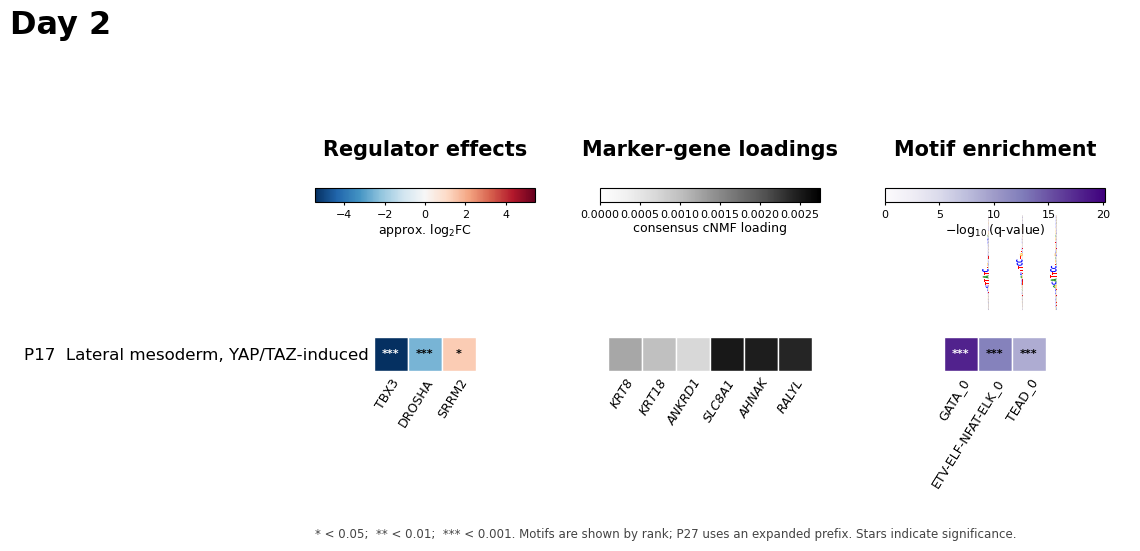

Saved D2:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D2_P17.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D2_P17.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D2_P17.png


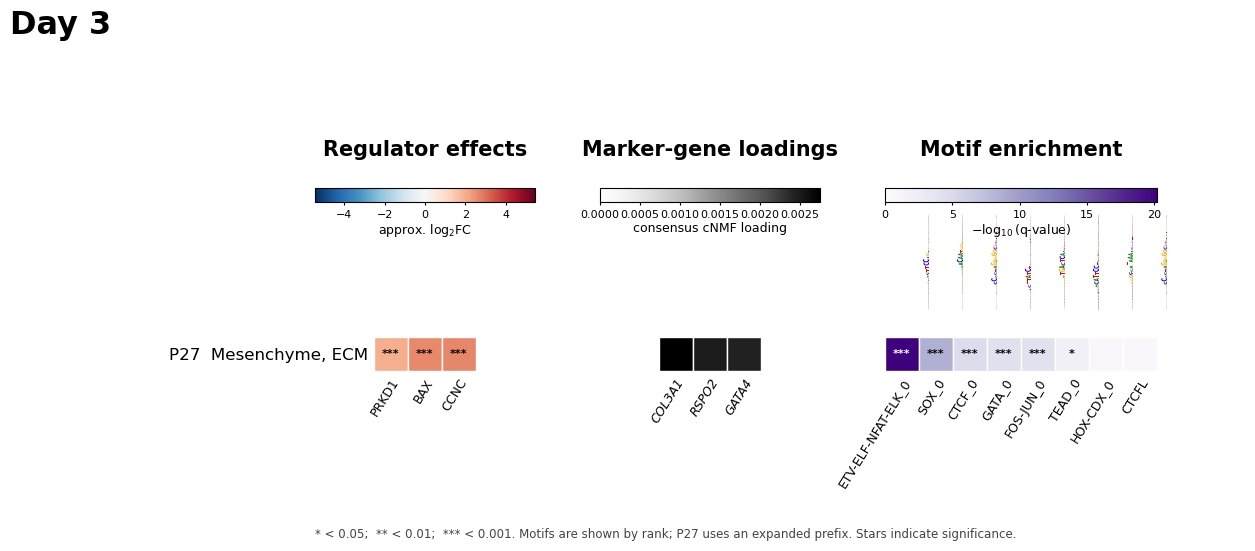

Saved D3:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D3_P27.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D3_P27.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_D3_P27.png

Rendering the combined D2 P17 / D3 P27 figure with shared color scales across the two program-day pairs...


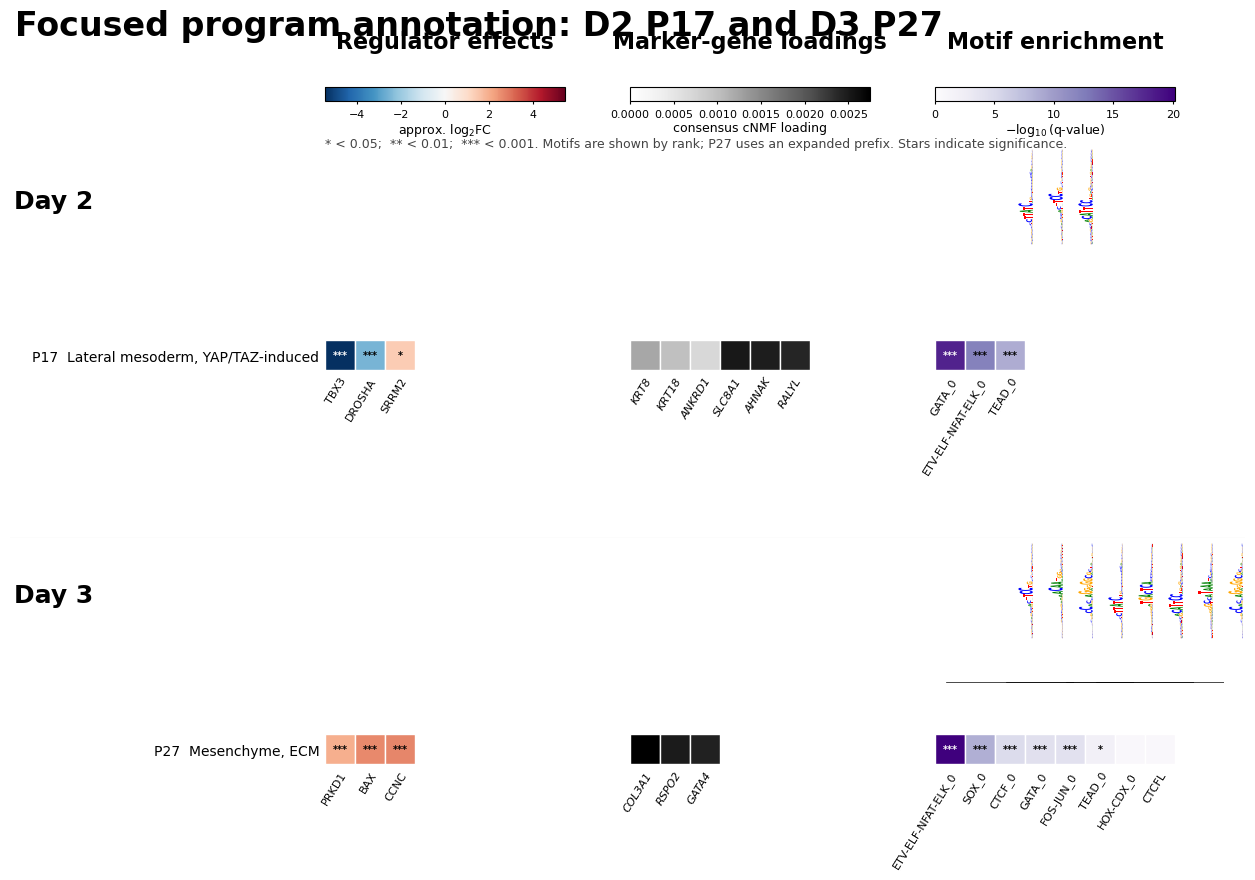

Saved combined figure:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_combined.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_combined.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/P17_D2_P27_D3_annotation_motif_rank_v3/Program_annotation_D2_P17_D3_P27_combined.png


In [8]:

# ============================================================
# RENDER PER-DAY PANELS AND COMBINED D0-D3 FIGURE
# ============================================================

if MAKE_PER_DAY_PANELS:
    print(
        "Rendering per-day panels with programs as rows, "
        "motifs as columns, and 90-degree rotated logos..."
    )

    for day in DAYS_TO_PLOT:
        if day not in day_packages:
            print(
                f"[skip] {day}: no package"
            )
            continue

        output_stem = make_per_day_panel(
            day=day,
            day_package=day_packages[day],
            shared_scales=shared_scales,
        )

        print(f"Saved {day}:")
        print(
            " ",
            output_stem.with_suffix(".svg"),
        )
        print(
            " ",
            output_stem.with_suffix(".pdf"),
        )
        print(
            " ",
            output_stem.with_suffix(".png"),
        )


if MAKE_COMBINED_ALL_DAYS_FIGURE:
    print(
        "\nRendering the combined D2 P17 / D3 P27 figure "
        "with shared color scales across the two program-day pairs..."
    )

    combined_output_stem = (
        make_combined_all_days_figure(
            day_packages=day_packages,
            days=DAYS_TO_PLOT,
            shared_scales=shared_scales,
        )
    )

    print("Saved combined figure:")
    print(
        " ",
        combined_output_stem.with_suffix(
            ".svg"
        ),
    )
    print(
        " ",
        combined_output_stem.with_suffix(
            ".pdf"
        ),
    )
    print(
        " ",
        combined_output_stem.with_suffix(
            ".png"
        ),
    )
